<center><p float="center">
  <img src="https://www.foodrepublic.com/img/gallery/why-estate-wine-is-so-much-more-expensive/intro-1702567133.jpg" width="720"/>
</p></center>

<center><font size=6>Wine Quality Prediction</font></center>

## Problem Statement

### Context:

'GrapeVine Estates' is a prominent wine manufacturing company. Traditionally, their wine quality is assessed by human wine-tasters at the end of the production cycle. This manual process is time-consuming, expensive, and subject to human bias. The Quality Control department wants to modernize this workflow by predicting the quality of the wine immediately after the laboratory chemical tests are concluded. You, as a data scientist, are tasked with building a predictive model to automate this quality assessment.

### Objective:
To build a supervised machine learning model that predicts the 'Quality Score' (from 0 to 10) of a wine based solely on its physicochemical test results, thereby reducing reliance on human tasting and speeding up the production pipeline.

**Key questions to be answered**

- Which physicochemical properties (e.g., alcohol, volatile acidity) are the strongest predictors of wine quality?
- Does a higher concentration of residual sugar or alcohol guarantee a higher quality rating?   
- Can we accurately classify a wine as "Good" (quality $\ge$ 7) or "Bad" (quality $<$ 7) using only chemical thresholds?   

### Data Description:

- fixed acidity: Most acids involved with wine or fixed or nonvolatile (do not evaporate readily).   
- volatile acidity: The amount of acetic acid in wine, which at too high of levels can lead to an unpleasant, vinegar taste.   
- citric acid: Found in small quantities, citric acid can add 'freshness' and flavor to wines.   
- residual sugar: The amount of sugar remaining after fermentation stops.
- chlorides: The amount of salt in the wine.
- free sulfur dioxide: The free form of SO2 exists in equilibrium between molecular SO2 (as a dissolved gas) and bisulfite ion.
- total sulfur dioxide: Amount of free and bound forms of SO2.
- density: The density of wine is close to that of water depending on the percent alcohol and sugar content.
- pH: Describes how acidic or basic a wine is on a scale from 0 (very acidic) to 14 (very basic).
- sulphates: A wine additive which can contribute to sulfur dioxide gas (SO2) levels.
- alcohol: The percent alcohol content of the wine.
- quality: Output variable (based on sensory data, score between 0 and 10).

### Domain Information:

- Supervised Learning: Machine learning where the model is trained on labeled data (here, the quality column is the label).
- Sensory Assessment: The traditional method of judging wine using human senses (taste, smell, and sight).
- Physicochemical Tests: Objective laboratory tests that measure the exact chemical makeup of a substance.

## Importing necessary libraries

**Let's start by importing libraries we need.**

In [ ]:
# Data Handling & Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# Baseline & Ensemble Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)
from xgboost import XGBClassifier

from sklearn.model_selection import RandomizedSearchCV

# Warnings ignore
import warnings
warnings.filterwarnings("ignore")

## Reading the dataset

In [ ]:
# Mount the drive into colab notebook
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Loading the data
data = pd.read_csv("/content/drive/MyDrive/Datasets [ML Pipeline]/winequality.csv", sep = ";")

## Overview of the dataset

### View the first 5 rows of the dataset

In [ ]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Check data types and number of non-null values for each column

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


- **Dataset Size:** The dataset contains 1,599 rows and 12 columns (11 input features and 1 quality column), using only 150.0 KB of memory.

- **No Missing Values:** Every column has 1,599 non-null entries, meaning there are no missing values to impute or drop.

- **All Numerical Features:** All 11 physicochemical features are float64 and quality is int64, so no categorical encoding is required before modeling.

- **Target Column Note:** The quality column is currently an integer (int64), which is later converted into the binary target column (premium) for classification.

In [ ]:
data.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


- There are no missing values in the data.

### Summary of the dataset

In [ ]:
# Summary of continuous columns
data.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


- **Potential Outliers & Right Skewness:** Features like residual sugar (75% at 2.6 vs. max 15.5), total sulfur dioxide (75% at 62.0 vs. max 289.0), free sulfur dioxide (75% at 21.0 vs. max 72.0), and chlorides (75% at 0.09 vs. max 0.611) have maximum values far above their 75th percentiles, indicating right-skewed distributions with high-end outliers.

- **Wide Range of Scales:** Feature magnitudes vary greatly—from chlorides (mean 0.087) and density (mean 0.997) up to total sulfur dioxide (mean 46.47, max 289.0). Tree-based ensemble models handle this naturally without scaling.

- **Tightly Clustered Features:** density (std = 0.0019) and pH (mean 3.31, median 3.31, std = 0.15) show very little spread and are nearly symmetric.

- **Target (quality) Distribution:** Scores range from 3 to 8, with an average of 5.64 and a median of 6.0, showing that most wines fall in the middle quality range (5–6).

### Number of unique values in each column

In [ ]:
data.nunique()

,0
fixed acidity,96
volatile acidity,143
citric acid,80
residual sugar,91
chlorides,153
free sulfur dioxide,60
total sulfur dioxide,144
density,436
pH,89
sulphates,96


- **Discrete Target (quality):** Contains only 6 unique values (ratings 3 to 8), confirming it is a discrete score suitable for classification rather than a continuous variable.

- **Continuous Input Features:** All 11 physicochemical features have between 60 and 436 unique values, confirming they are continuous numerical measurements.

- **Highest & Lowest Variety:** density has the most unique values (436), while free sulfur dioxide (60) and alcohol (65) have the fewest among the input features.

- **No Constant or ID Columns:** No column has just 1 unique value (zero variance) or 1,599 unique values (an ID column), meaning every feature has useful variation for modeling.


### Create a new column called `premium`.


In [ ]:
data['premium'] = (data['quality'] >= 6).astype(int)

print(data['premium'].value_counts())

premium
1    855
0    744
Name: count, dtype: int64


- 1 means premium wine (quality 6 or more)
- 0 means not premium wine (quality below 6)

## <a name='link2'>Exploratory Data Analysis (EDA) Summary</a>

**Note:** The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA.

**The below functions need to be defined to carry out the EDA**

In [ ]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
### Function to plot distributions


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

### Univariate Analysis

#### `fixed acidity`

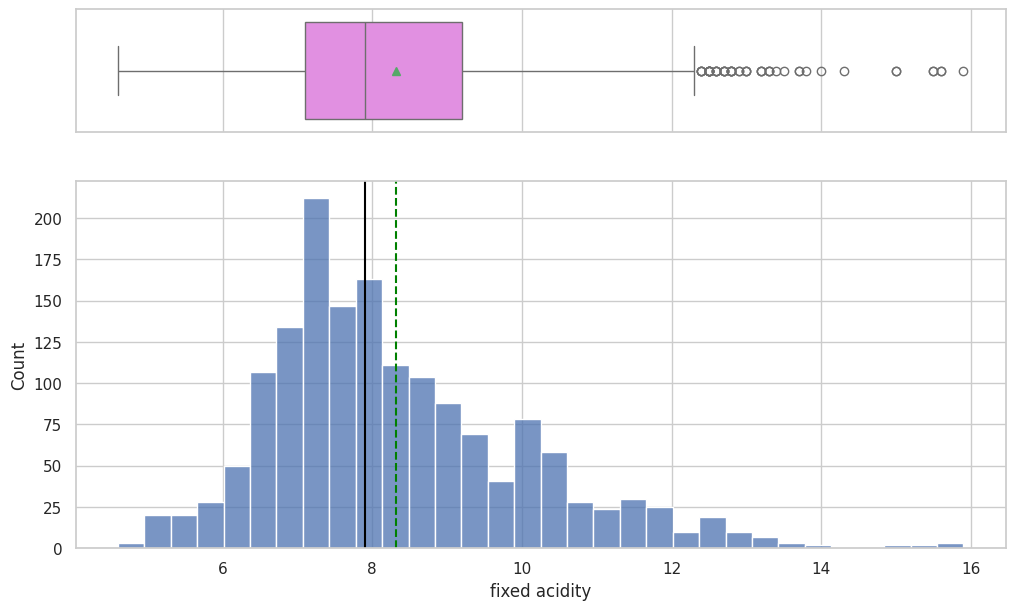

In [ ]:
histogram_boxplot(data, "fixed acidity")

- **Right-Skewed Distribution:** The fixed acidity data is moderately skewed to the right, with a long tail stretching toward higher values up to 16.   
- **Mean vs. Median:** Because of the right skew, the mean (dashed green line, around 8.3) is pulled slightly higher than the median (solid black line, around 7.9).   
- **Typical Range:** Most values are concentrated between 7 and 9.2, with the highest peak occurring just above 7.   
- **High-End Outliers:** The hollow circles on the right side of the top boxplot show several high-acidity outliers, starting above 12 and reaching nearly 16.

#### `volatile acidity`

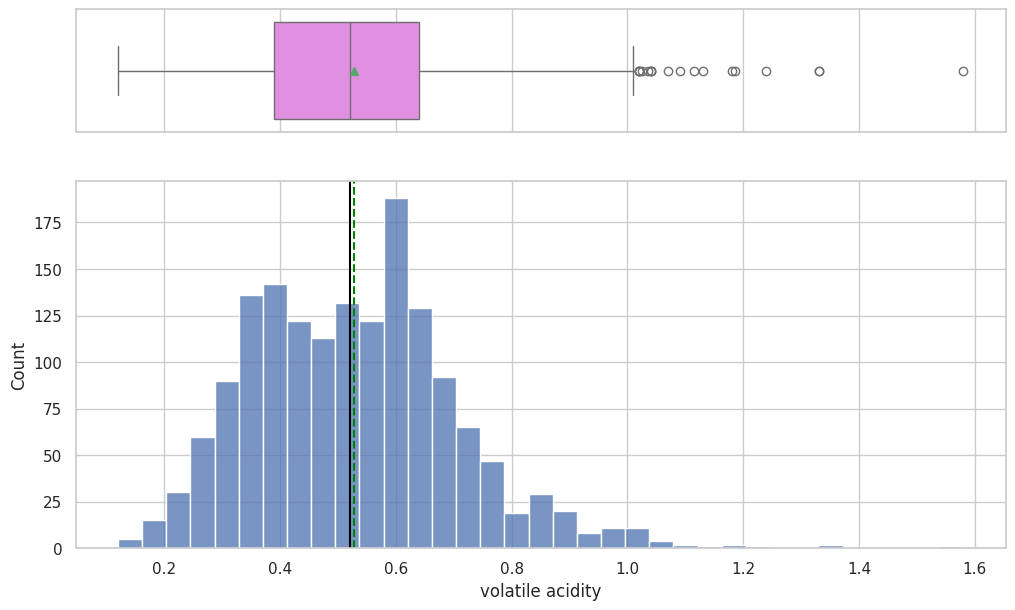

In [ ]:
histogram_boxplot(data, "volatile acidity")

- **Slightly Right-Skewed:** The volatile acidity distribution is mildly skewed to the right, with a tail extending out toward higher values.   
- **Balanced Center:** The mean (dashed green line, around 0.53) and median (solid black line, around 0.52) are almost identical, showing that the core data is fairly well-centered.   
- **Two Main Peaks:** Most values fall between 0.35 and 0.70, with two noticeable peaks—one near 0.40 and the highest peak right around 0.60.   
- **High-End Outliers:** The hollow circles on the right side of the top boxplot reveal several outliers starting just above 1.0 and reaching nearly 1.6

#### `citric acid`

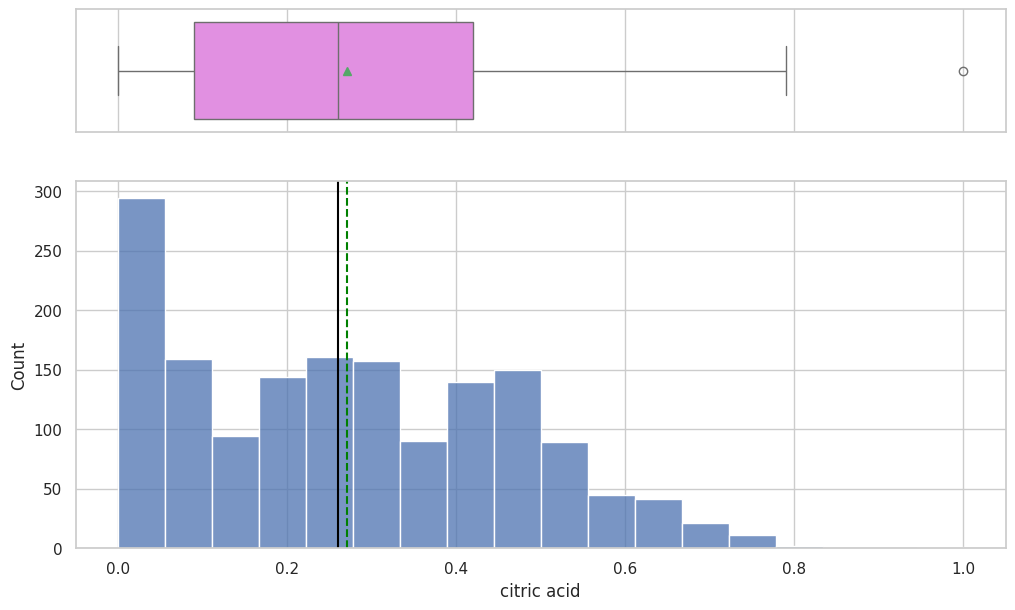

In [ ]:
histogram_boxplot(data, "citric acid")

- **High Zero/Low Concentration:** The tallest bar is right at 0.0 (nearly 300 wines), showing that a large number of wines contain little to no citric acid.   
- **Balanced Center:** The mean (dashed green line, around 0.27) and median (solid black line, around 0.26) are very close to each other.   
- **Broad Spread:** Most values are spread widely between 0.0 and 0.5, with smaller peaks around 0.25 and 0.48 before dropping off sharply after 0.5.   
- **Single Outlier:** Unlike the other acidity features, there is only one clear outlier on the far right of the boxplot, sitting right at 1.0.  

#### `residual sugar`

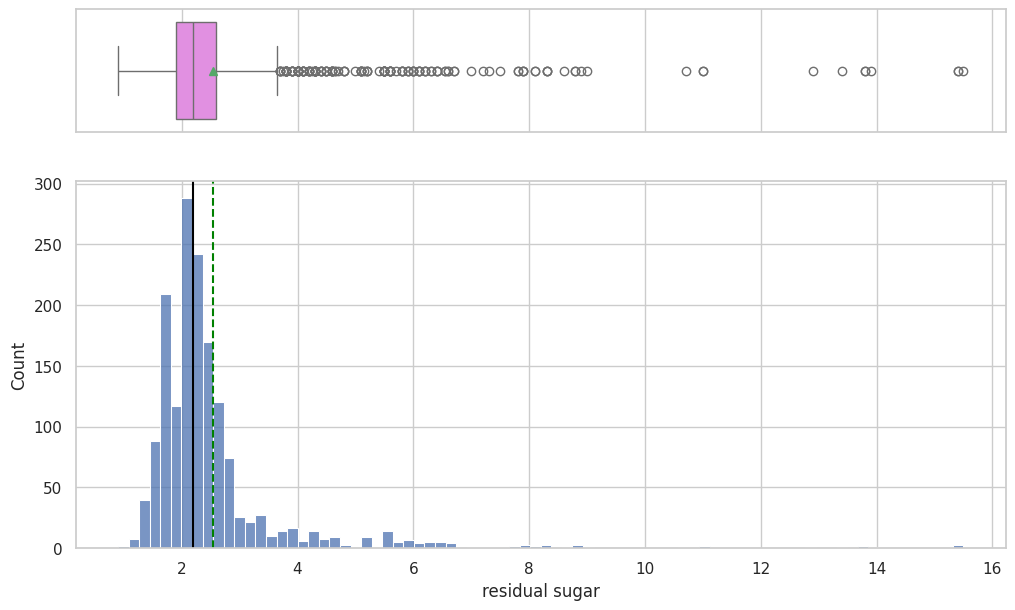

In [ ]:
histogram_boxplot(data, "residual sugar")

- **Heavily Right-Skewed:** The residual sugar distribution is strongly skewed to the right, with a very long tail stretching all the way out to around 15.5.   
- **Tight Core Cluster:** The vast majority of wines have low residual sugar, heavily concentrated between 1.5 and 3.0, with a sharp peak right around 2.0 to 2.2.   
- **Mean vs. Median:** Because of the high-value outliers, the mean (dashed green line, around 2.5) is pulled slightly higher than the median (solid black line, around 2.2).   
- **Numerous Outliers:** The top boxplot shows a very narrow interquartile range followed by a dense trail of outliers starting just above 3.6 and reaching over 15.

#### `chlorides`

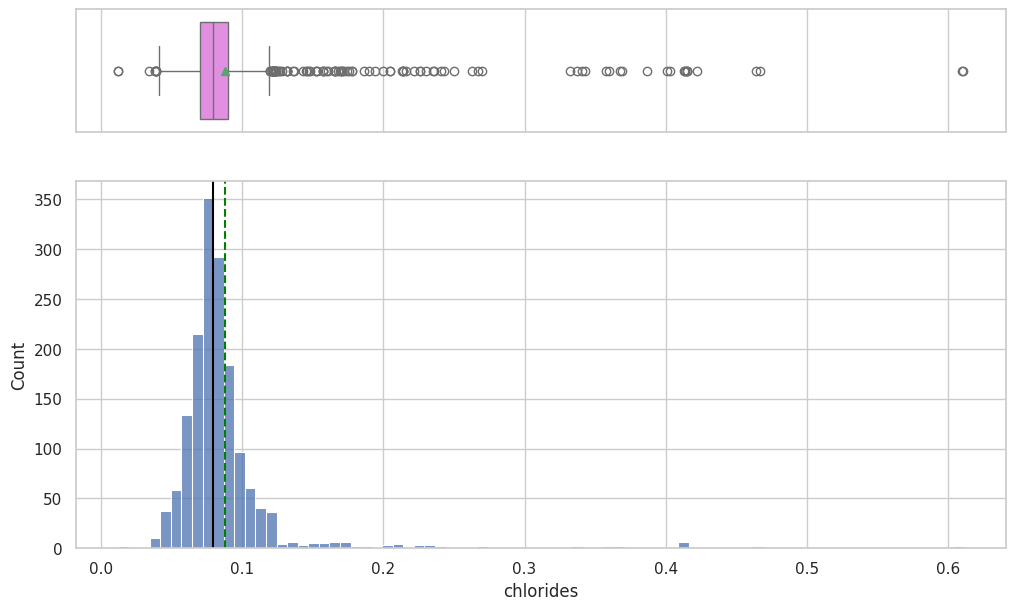

In [ ]:
histogram_boxplot(data, "chlorides")

- **Heavily Right-Skewed:** The chlorides distribution is strongly skewed to the right, with a long tail stretching past 0.6.   
- **Very Tight Core:** The vast majority of wines have low chloride levels, tightly concentrated between 0.05 and 0.12 with a sharp peak near 0.08.   
- **Mean vs. Median:** The mean (dashed green line, around 0.09) is pulled slightly higher than the median (solid black line, around 0.08) due to extreme high values.   
- **Outliers on Both Ends:** The top boxplot shows a very narrow main range, a few low-end outliers below 0.04, and a dense trail of high-end outliers starting above 0.12 and reaching over 0.6.

#### `free sulfur dioxide`

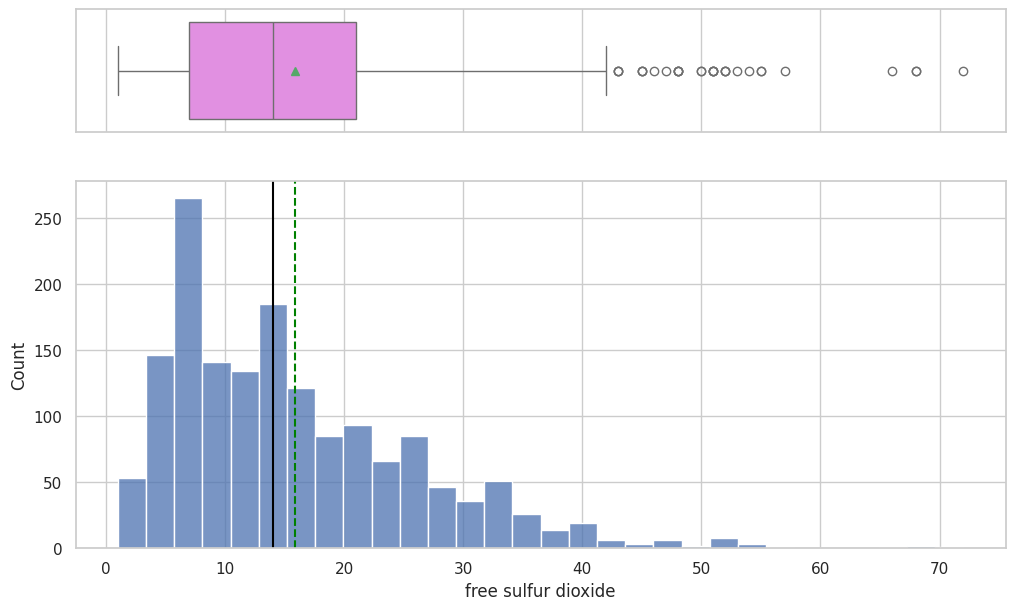

In [ ]:
histogram_boxplot(data, "free sulfur dioxide")

- **Right-Skewed Distribution:** The free sulfur dioxide data is strongly skewed to the right, with a long tail stretching out past 70.   
- **Mean vs. Median:** Due to the right skew, the mean (dashed green line, around 16) is pulled slightly higher than the median (solid black line, around 14).   
- **Typical Range:** Most values are concentrated between 5 and 25, with the highest peak occurring around 6 to 8.   
- **High-End Outliers:** The top boxplot shows several outliers on the right side, starting just above 42 and reaching up to around 72.   

#### `total sulfur dioxide`

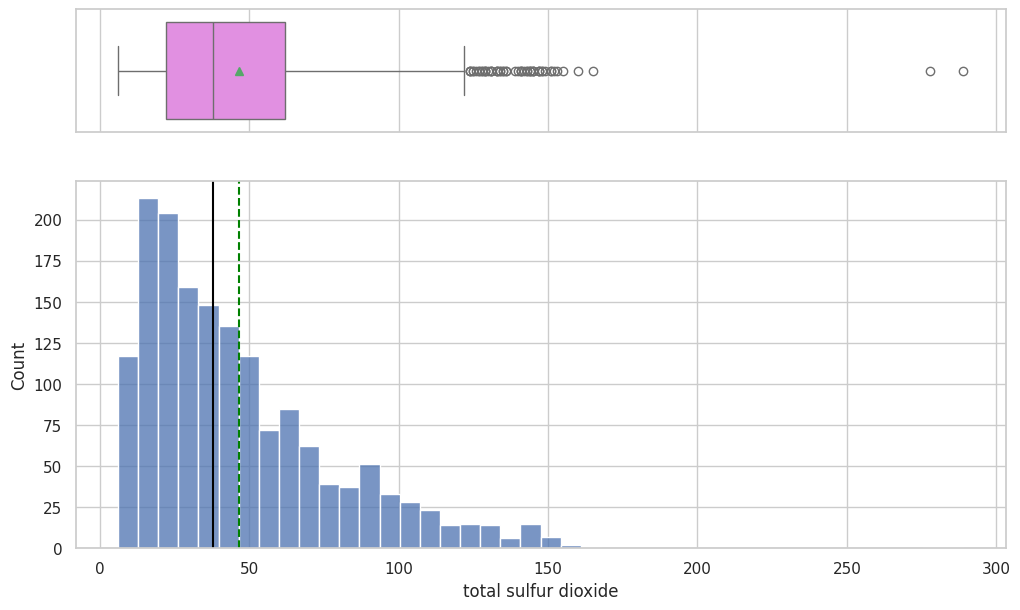

In [ ]:
histogram_boxplot(data, "total sulfur dioxide")

- **Heavily Right-Skewed:** The total sulfur dioxide distribution is strongly skewed to the right, with a long tail stretching out toward nearly 300.   
- **Mean vs. Median:** Because of the right skew, the mean (dashed green line, around 46) is pulled noticeably higher than the median (solid black line, around 38).   
- **Typical Range:** Most values are concentrated between 10 and 70, with the highest peak occurring around 15 to 25.   
- **Extreme Outliers:** The top boxplot shows a cluster of outliers starting just above 120 up to around 165, along with two extreme, isolated outliers sitting far to the right near 280–290.

#### `density`

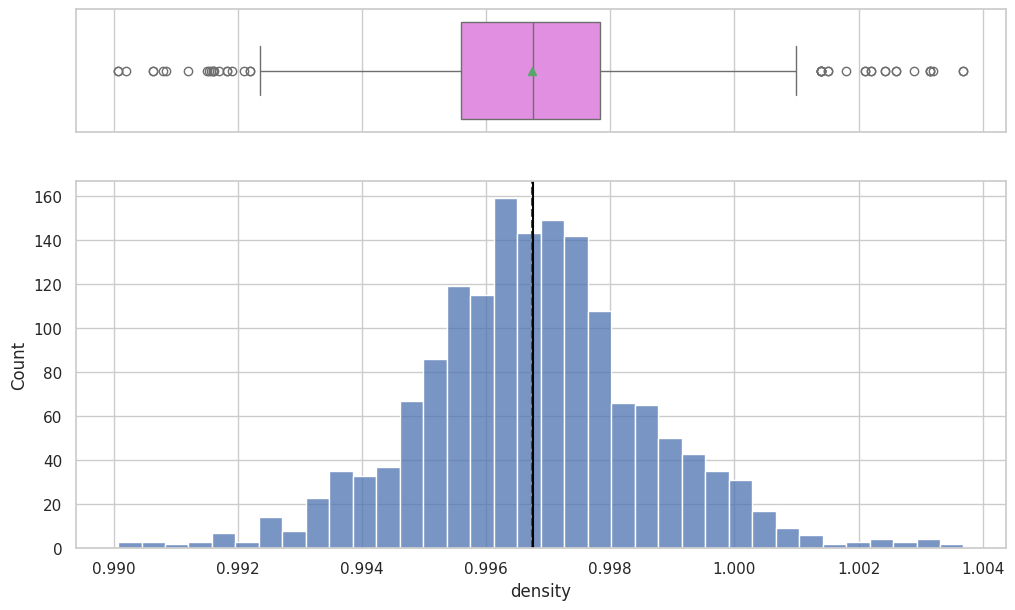

In [ ]:
histogram_boxplot(data, "density")

- **Normal (Bell-Shaped) Distribution:** The density data is very symmetric and closely follows a normal distribution, unlike the skewed features before it.   
- **Identical Mean and Median:** Because the data is so balanced, the mean (green triangle/dashed line) and median (solid black line) overlap almost perfectly right around 0.9967.   
- **Tight Core Range:** Most wines have a density tightly clustered between 0.995 and 0.999, with the highest peak occurring around 0.996 to 0.9975.   
- **Balanced Outliers:** The top boxplot shows a fairly even spread of outliers on both ends—below 0.992 on the left and above 1.001 on the right.

#### `pH`

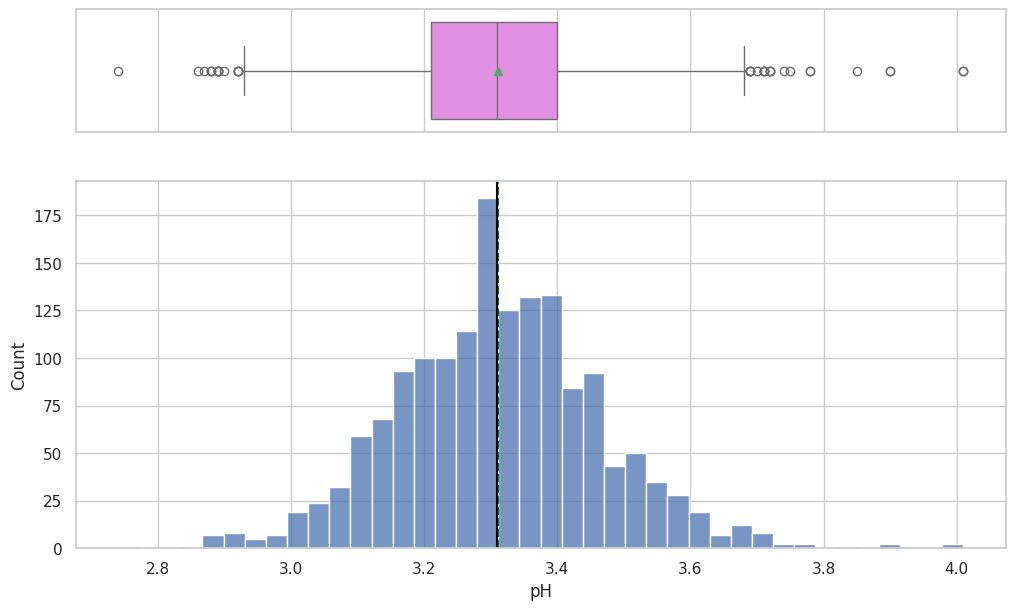

In [ ]:
histogram_boxplot(data, "pH")

- **Normal (Bell-Shaped) Distribution:** The pH data is symmetric and closely follows a normal distribution.   
- **Identical Mean and Median:** Because the distribution is well-balanced, the mean (dashed green line/triangle) and median (solid black line) overlap almost perfectly right around 3.31.   
- **Typical Range:** Most wines have a pH concentrated between 3.1 and 3.5, with the sharpest peak occurring right around 3.3.   
- **Outliers on Both Ends:** The top boxplot shows outliers on both sides—below ~2.93 on the low end (down to ~2.74) and above ~3.68 on the high end (reaching up to 4.0).

#### `sulphates`

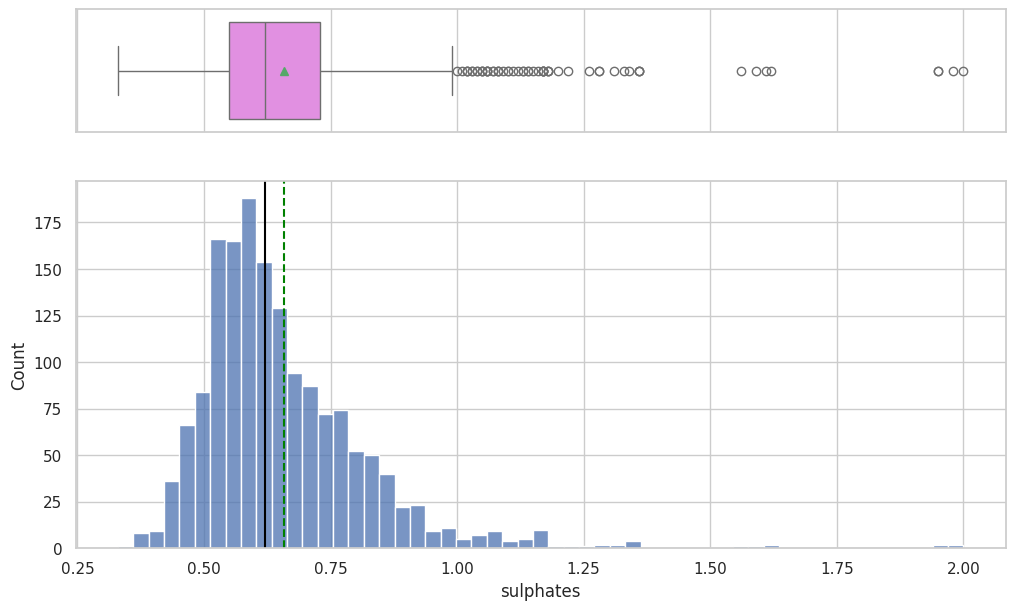

In [ ]:
histogram_boxplot(data, "sulphates")

- **Right-Skewed Distribution:** The sulphates data is strongly skewed to the right, with a long tail stretching all the way out to 2.0.   
- **Mean vs. Median:** Due to the right skew and extreme values, the mean (dashed green line, around 0.66) is pulled slightly higher than the median (solid black line, around 0.62).   
- **Typical Range:** Most wines have sulphate levels concentrated between 0.50 and 0.85, with the highest peak occurring around 0.55 to 0.60.   
- **High-End Outliers:** The top boxplot shows a large number of outliers on the right side, starting right around 1.0 and reaching up to 2.0.

#### `alcohol`

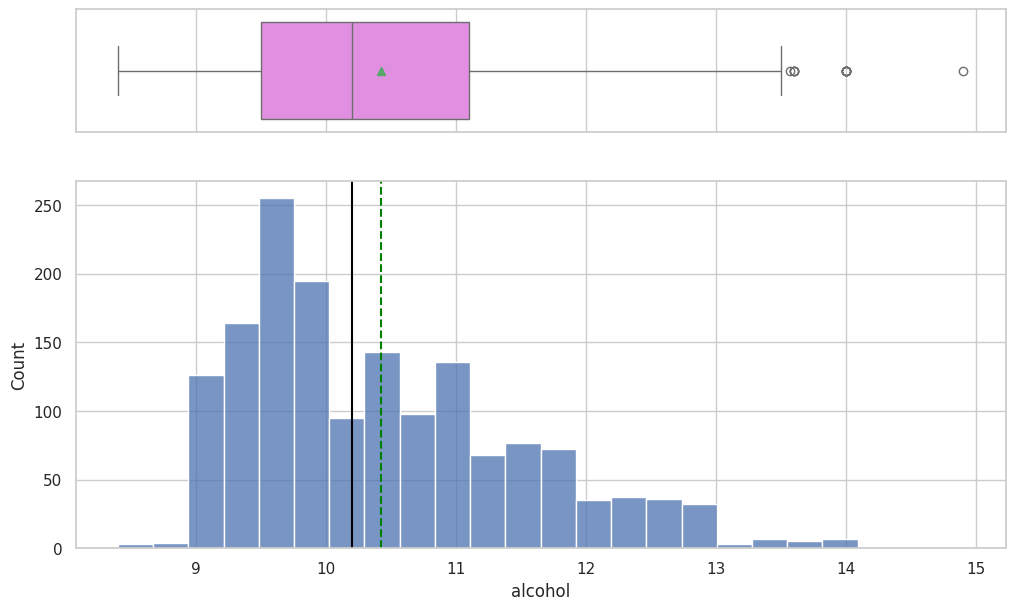

In [ ]:
histogram_boxplot(data, "alcohol")

- **Right-Skewed Distribution:** The alcohol data is moderately skewed to the right, with a tail gradually tapering off toward 15.   
- **Mean vs. Median:** Because of the right skew, the mean (dashed green line, around 10.4) is pulled slightly higher than the median (solid black line, around 10.2).   
- **Typical Range:** Most wines have an alcohol content between 9.0 and 12.0, with the sharpest peak occurring right around 9.5 to 9.8.   
- **Few High-End Outliers:** Unlike several other features, alcohol has very few outliers—only a handful of points on the right side of the boxplot above 13.5, reaching nearly 15.  

#### `quality`

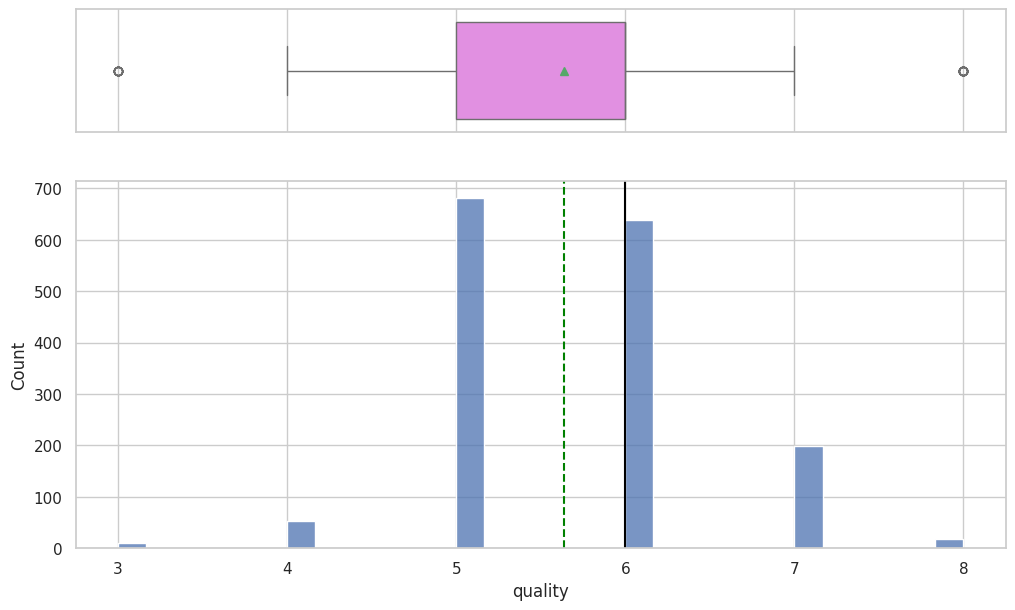

In [ ]:
histogram_boxplot(data, "quality")

- **Discrete Values:** Unlike the other continuous features, quality consists of discrete integer ratings ranging from 3 to 8.   
- **Heavily Concentrated in the Middle:** The vast majority of wines are rated 5 (around 680) or 6 (around 640), showing a strong class imbalance.   
- **Mean vs. Median:** The median (solid black line) sits right at 6, while the mean (dashed green line) is pulled slightly lower to around 5.6 due to the high volume of 5-rated wines.   
- **Rare Extreme Ratings:** Very few wines receive extreme scores—ratings of 3 and 8 are so uncommon that the top boxplot flags them as outliers on both ends.

#### `premium`

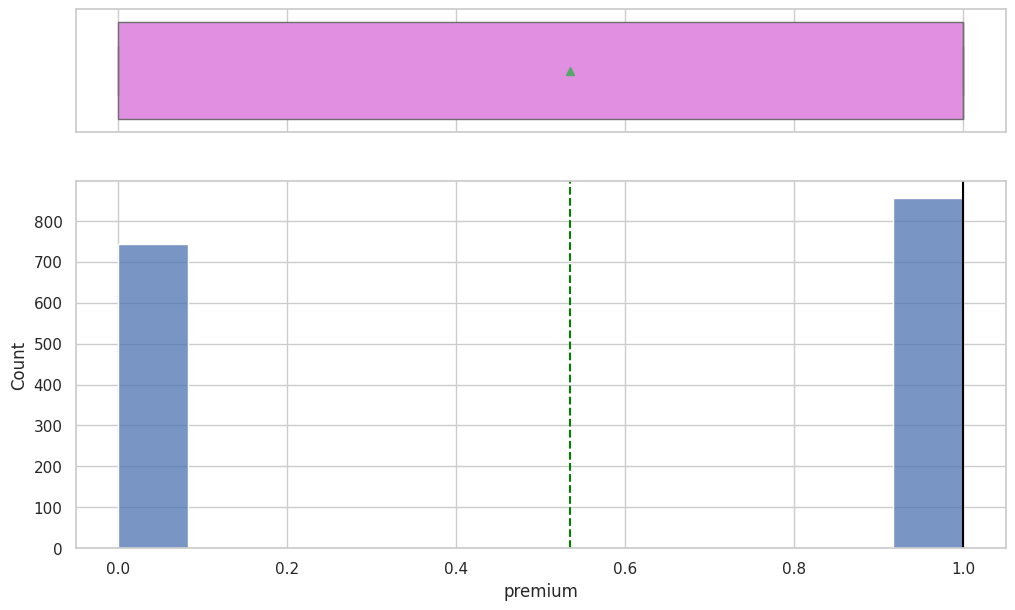

In [ ]:
histogram_boxplot(data, "premium")

- **Binary Target:** The premium column contains only two discrete values: 0 and 1.   
- **Well-Balanced Classes:** Both classes are fairly evenly split, with roughly 740 samples in class 0 and about 855 samples in class 1. This is ideal for training a classification model since there is no major class imbalance.   
- **Mean vs. Median:** Because class 1 makes up slightly more than half of the dataset, the median (solid black line) sits right at 1.0, while the mean (dashed green line) is around 0.53.   
- **Boxplot Shape:** Since the data is strictly binary, the top boxplot simply spans the entire range from 0.0 to 1.0 with no whiskers or outliers.

### Bivariate Analysis

#### `fixed acidity vs premium`

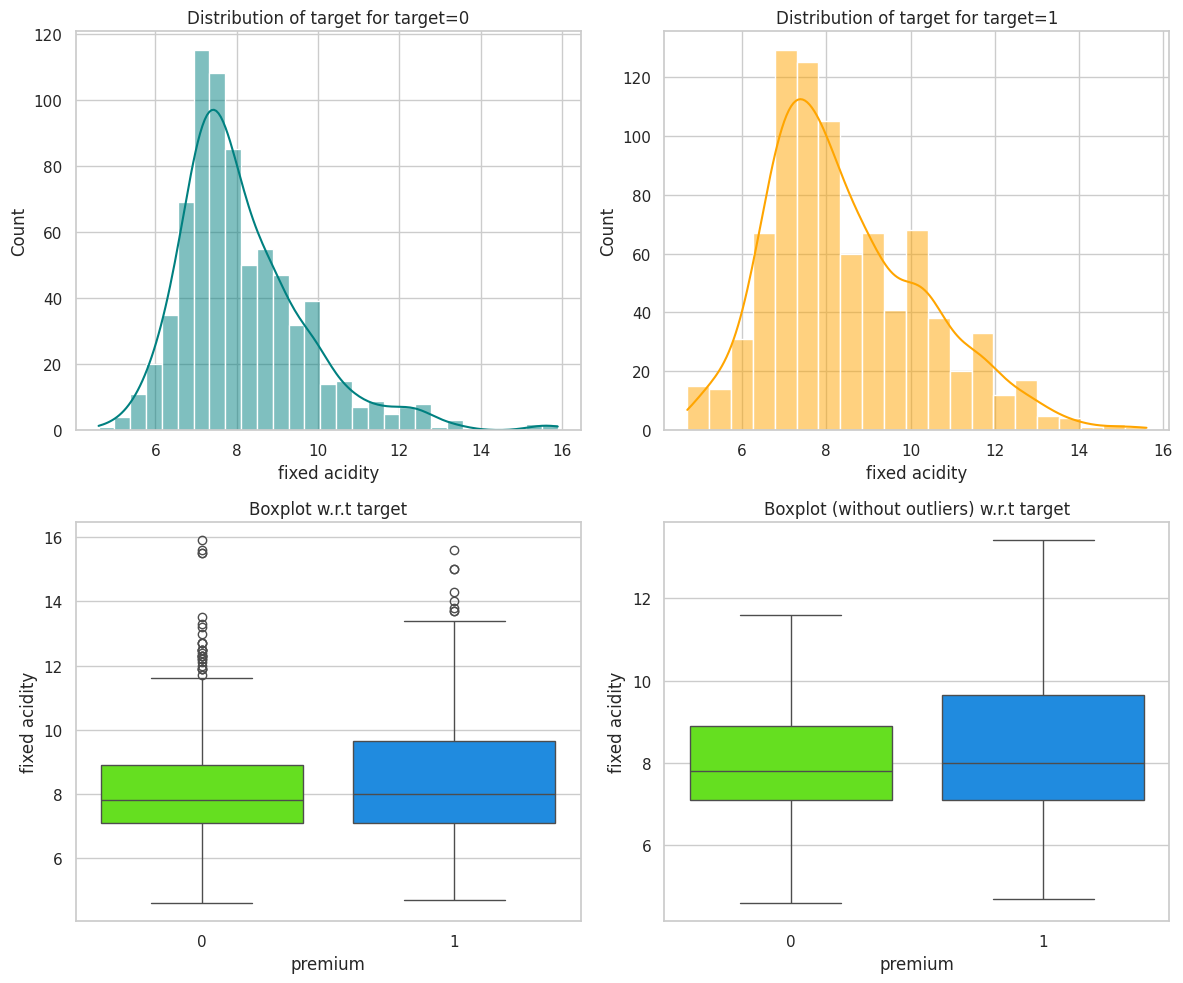

In [ ]:
distribution_plot_wrt_target(data, "fixed acidity", "premium")

- **Similar Right-Skewed Shapes:** Both target=0 and target=1 have right-skewed fixed acidity distributions that peak around 7 to 8.   
- **Slightly Higher Values for Premium:** Looking at the boxplots, premium=1 has a slightly higher median (around 8.0 vs. 7.8) and a wider upper spread, with its 75th percentile reaching nearly 9.7 compared to ~8.9 for premium=0.   
- **Heavy Overlap:** Both classes share almost the exact same lower range (around 4.6 to 7.1) and overlap heavily in the middle, making fixed acidity alone a weak separator between the two classes.   
- **Outlier Differences:** Non-premium wines (0) have a dense cluster of high-end outliers starting above 11.6, whereas premium wines (1) have a higher upper whisker (~13.4) and noticeably fewer outliers.   

#### `volatile acidity vs premium`

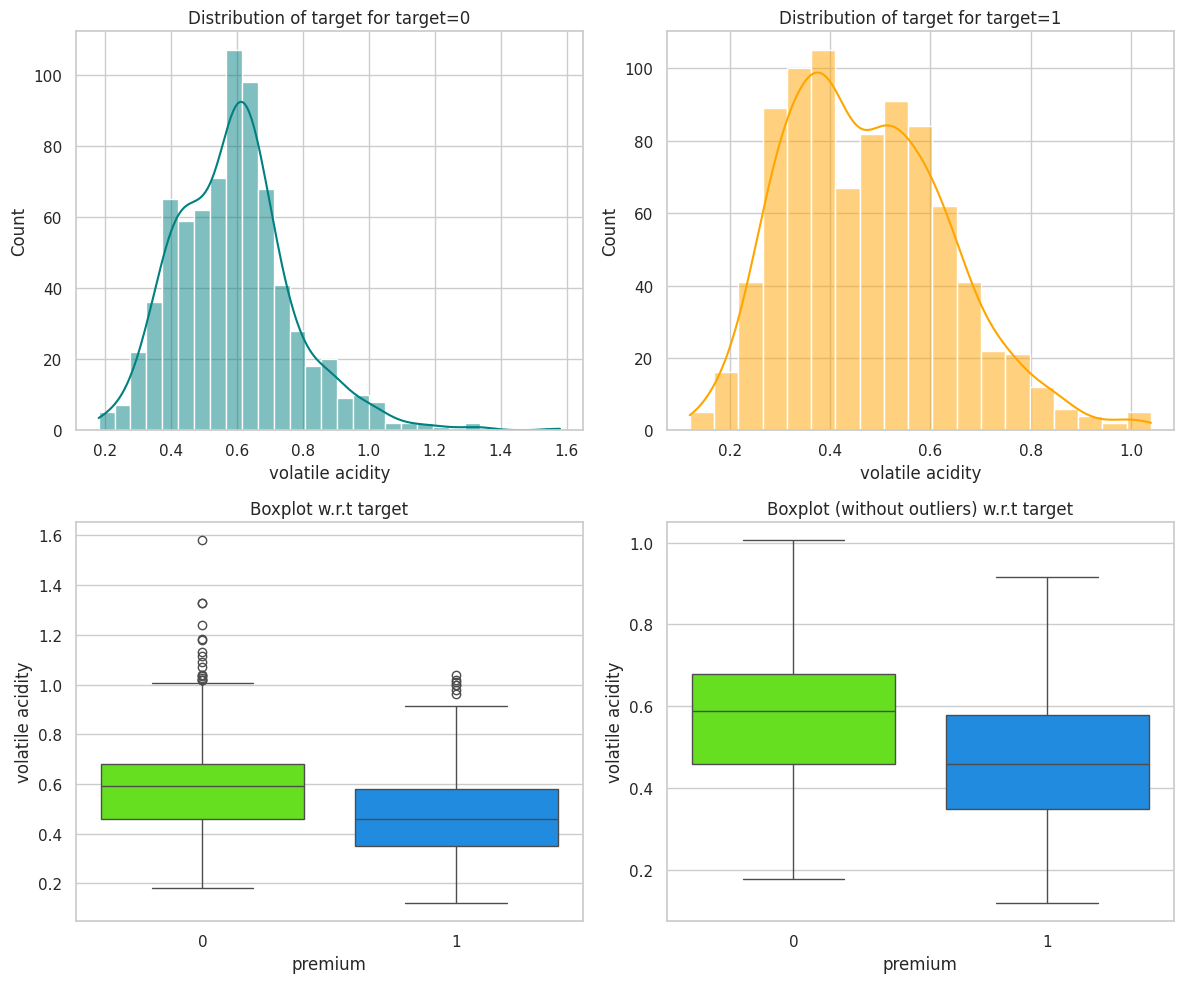

In [ ]:
distribution_plot_wrt_target(data, "volatile acidity", "premium")

- **Clear Negative Relationship:** Premium wines (target=1) generally have noticeably lower volatile acidity than non-premium wines (target=0).   
- **Shifted Distributions:** The distribution for target=0 peaks sharply around 0.60, whereas target=1 is shifted lower with two main peaks around 0.38 and 0.55.   
- **Good Separation in Boxplots:** The median for premium=1 (around 0.46) is much lower than for premium=0 (around 0.59)—in fact, the median of class 0 sits above the 75th percentile of class 1, making volatile acidity a useful feature for separating the two classes.   
- **Outlier Differences:** Non-premium wines (0) have more extreme high-end outliers reaching up to nearly 1.6, while premium wines (1) have fewer outliers that stay close to 1.0.

#### `citric acid vs premium`

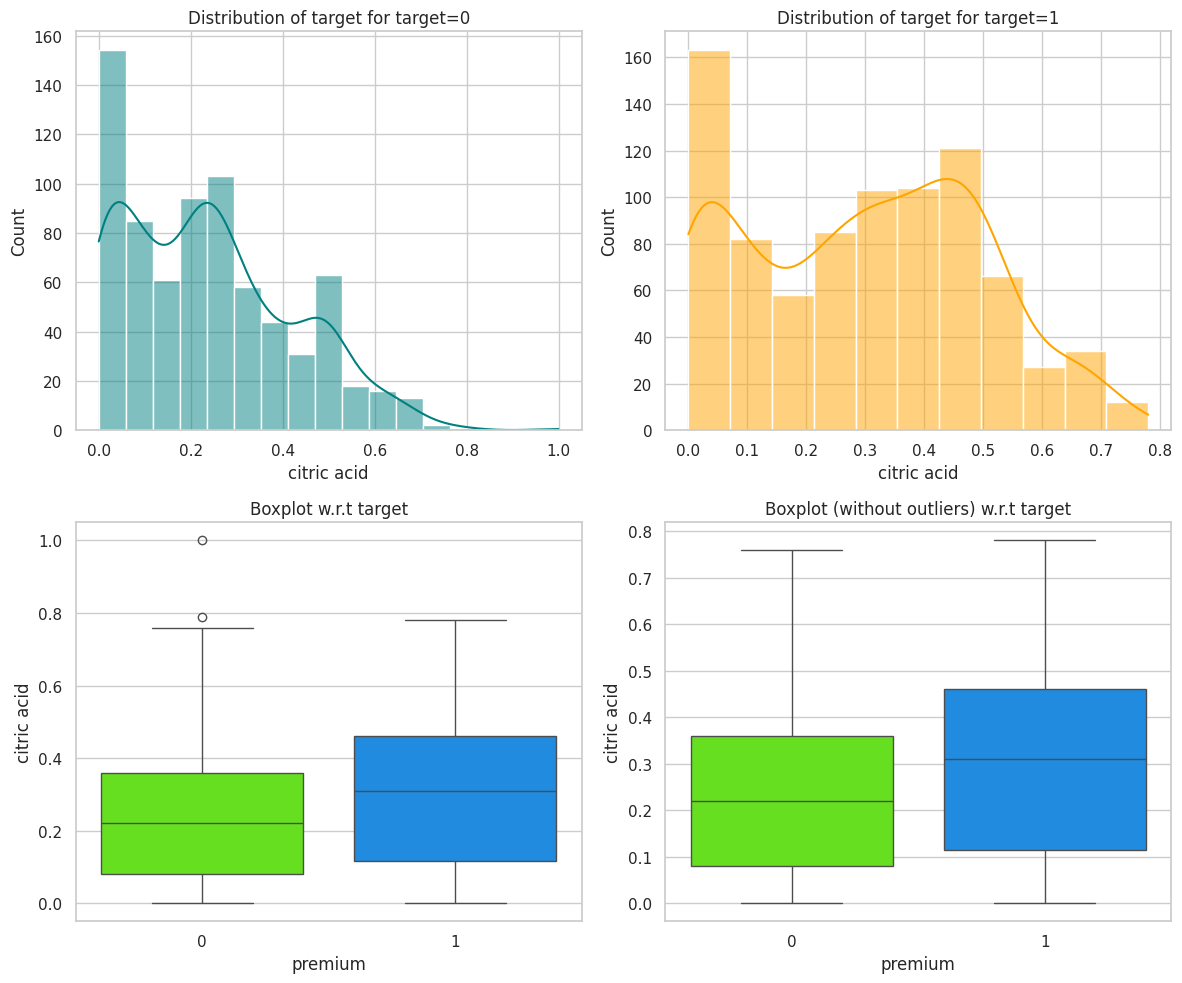

In [ ]:
distribution_plot_wrt_target(data, "citric acid", "premium")

- **Positive Relationship:** Premium wines (target=1) generally tend to have higher citric acid levels than non-premium wines (target=0).   
- **Shifted Secondary Peaks:** Both classes share a tall spike near 0.0, but target=0 has its next main peak around 0.25, whereas target=1 shifts higher with a prominent peak between 0.40 and 0.50.   
- **Higher Median & Spread for Premium:** Looking at the boxplots, premium=1 has a noticeably higher median (around 0.31 vs. 0.22) and a higher interquartile range (0.12–0.46 compared to 0.08–0.36 for premium=0).   
- **Minimal Outliers:** Non-premium wines (0) have only two high-end outliers (around 0.79 and 1.0), while premium wines (1) have no outliers at all.  

#### `residual sugar vs premium`

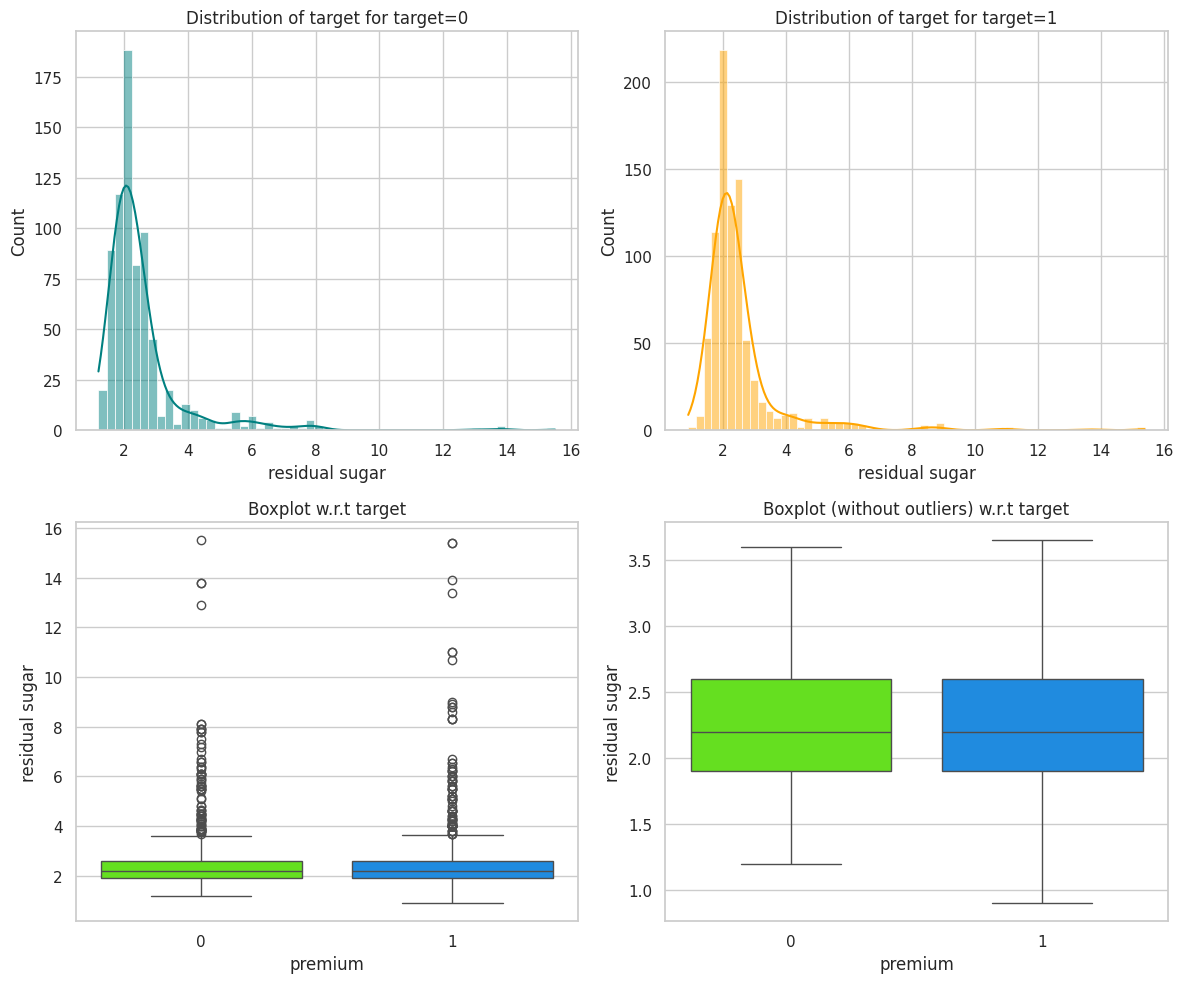

In [ ]:
distribution_plot_wrt_target(data, "residual sugar", "premium")

- **Nearly Identical Distributions:** Both target=0 and target=1 have heavily right-skewed residual sugar distributions with sharp peaks right around 2.0 to 2.2.   
- **Same Median and IQR:** Looking at the boxplots without outliers, both premium=0 and premium=1 share the exact same median (2.2) and interquartile range (1.9 to 2.6), with premium=1 only extending slightly lower at the bottom whisker (~0.9 vs. ~1.2).   
- **Heavy High-End Outliers:** Both classes have a dense trail of outliers starting just above 3.6 and reaching up to around 15.5.   
- **Very Weak Separator:** Because the distributions and core ranges overlap almost completely, residual sugar alone offers very little power to distinguish between premium and non-premium wines.   

#### `chlorides vs premium`

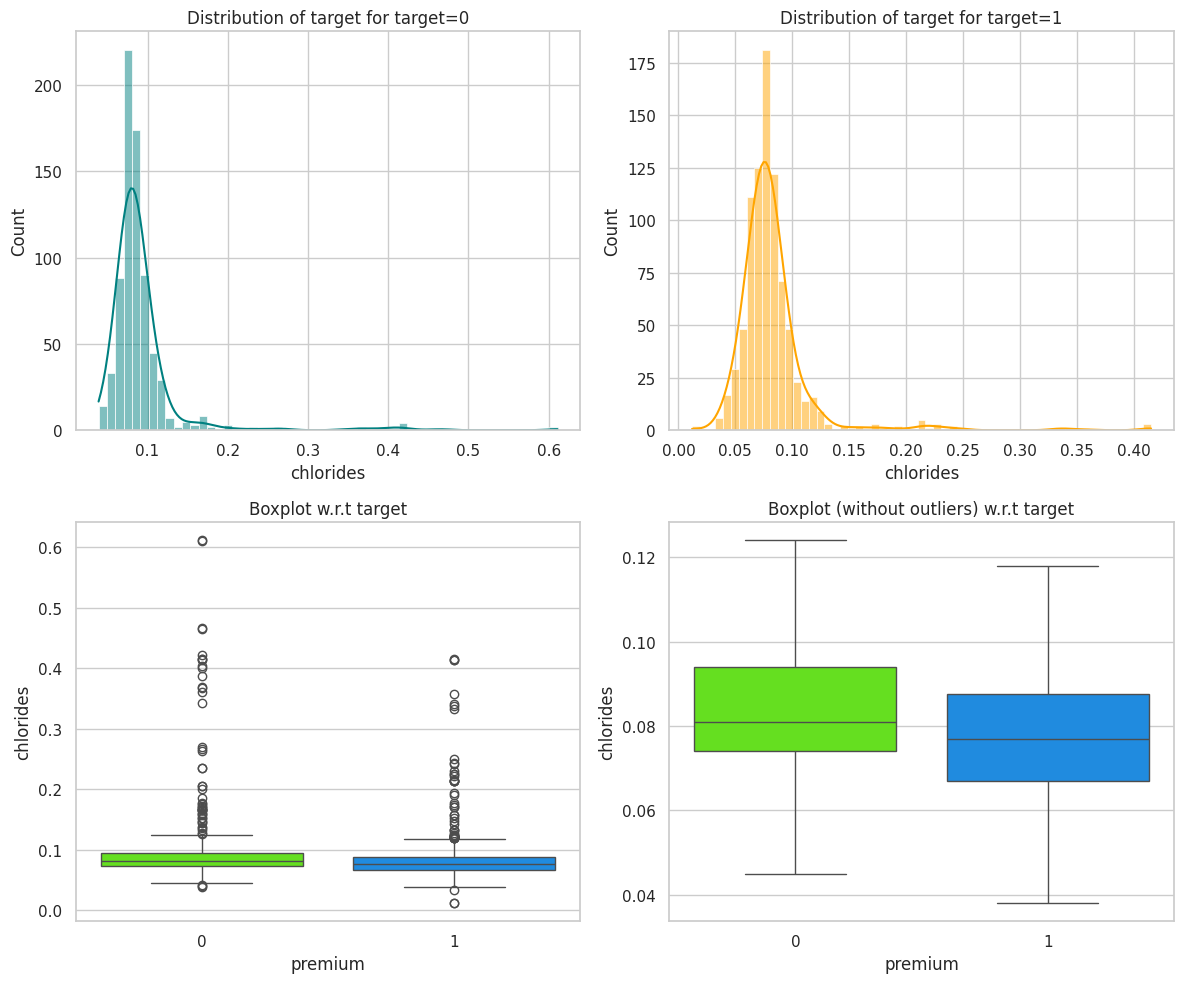

In [ ]:
distribution_plot_wrt_target(data, "chlorides", "premium")

- **Heavily Right-Skewed Distributions:** Both target=0 and target=1 are tightly clustered around a sharp peak near 0.075–0.08, with long right tails.   
- **Slightly Lower Levels for Premium:** Looking at the boxplots without outliers, premium=1 has a slightly lower median (around 0.077 vs. 0.081) and a slightly lower interquartile range (roughly 0.067–0.088 compared to 0.074–0.094 for premium=0).   
- **More Extreme Outliers in Non-Premium:** Both classes have dense trails of high-end outliers and a few low-end outliers, but premium=0 reaches higher extremes (up to ~0.61) compared to premium=1 (capping around ~0.41).   
- **Heavy Overlap:** Because the core ranges overlap significantly, chlorides alone provides only a weak separation between premium and non-premium wines.

#### `free sulfur dioxide vs premium`

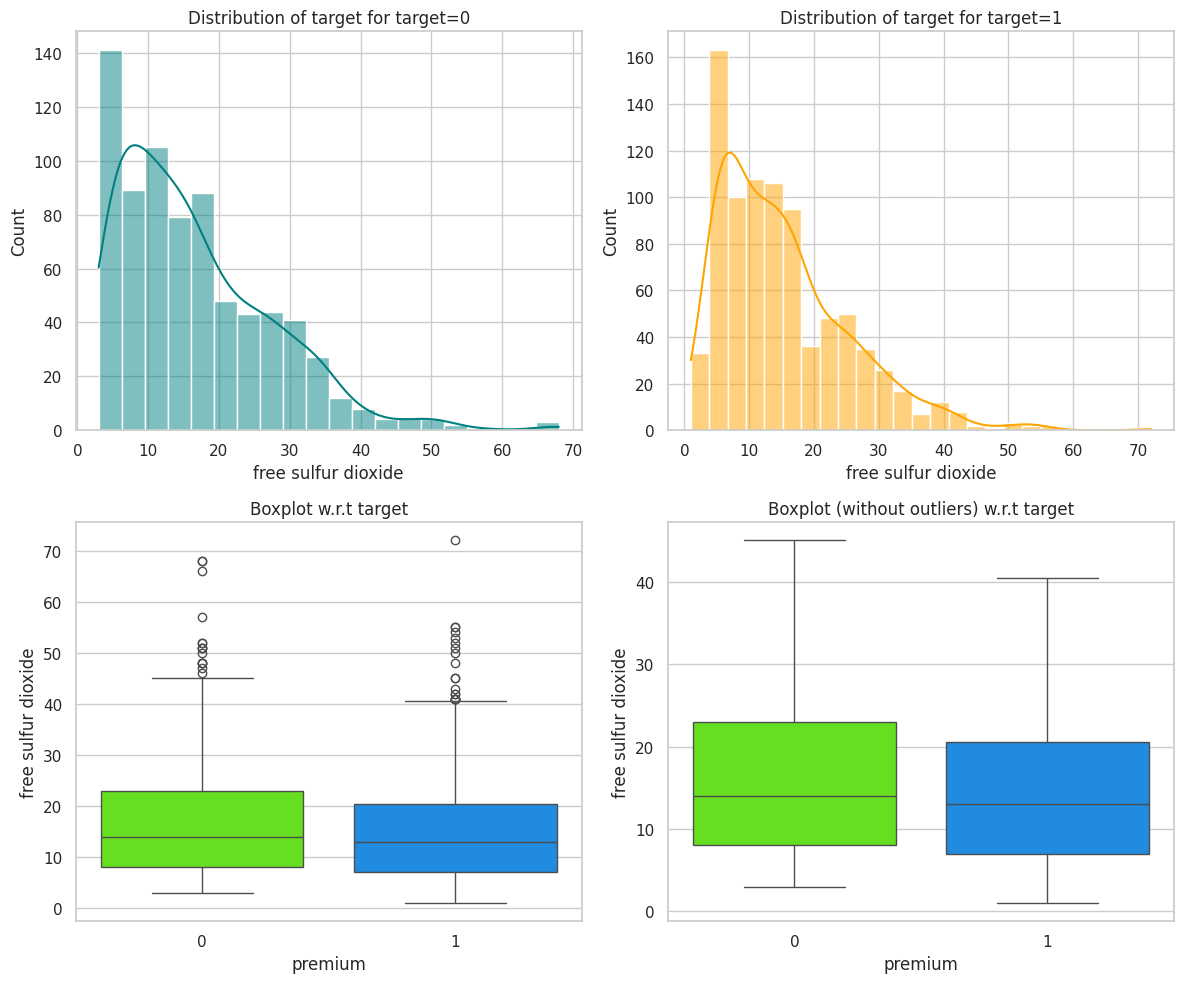

In [ ]:
distribution_plot_wrt_target(data, "free sulfur dioxide", "premium")

- **Similar Right-Skewed Shapes:** Both target=0 and target=1 have strongly right-skewed free sulfur dioxide distributions, peaking sharply around 5 to 7.   
- **Slightly Lower Values for Premium:** Looking at the boxplots without outliers, premium=1 sits slightly lower than premium=0, with a median around 13 (vs. 14) and an interquartile range of roughly 7–20.5 (compared to 8–23).   
- **High-End Outliers in Both Classes:** Both groups show several high-end outliers; premium=0 has outliers above 45 reaching up to ~68, while premium=1 has outliers starting just above 40 with one isolated extreme value near 72.   
- **Weak Separator:** Because the distributions and core ranges overlap heavily, free sulfur dioxide alone is a weak predictor for separating premium from non-premium wines.  

#### `total sulfur dioxide vs premium`

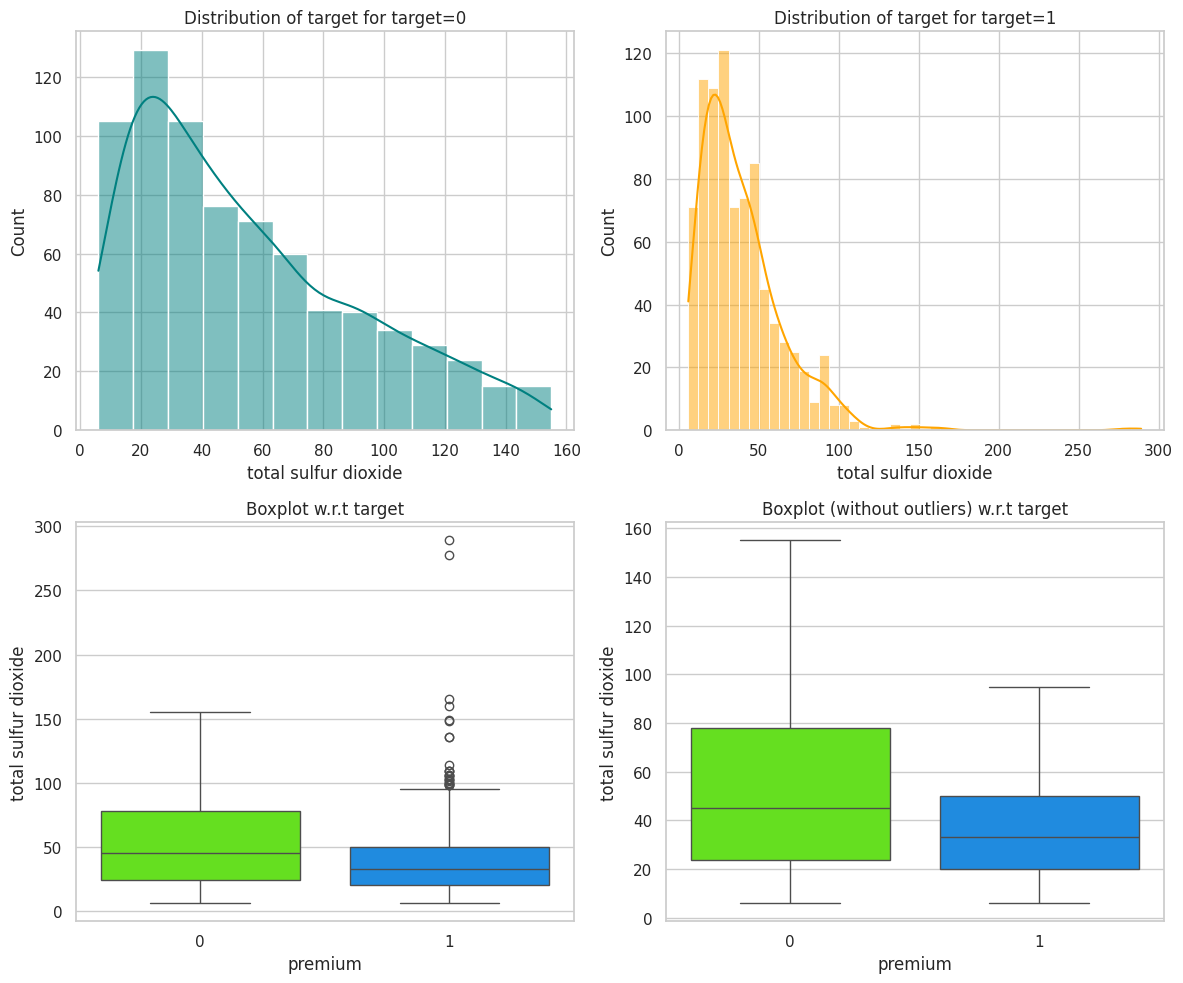

In [ ]:
distribution_plot_wrt_target(data, "total sulfur dioxide", "premium")

- **Right-Skewed Distributions:** Both target=0 and target=1 are right-skewed and peak around 20 to 30, but target=1 drops off much more sharply after 50 while target=0 spreads more gradually up to ~155.   
- **Noticeably Lower Levels for Premium:** Looking at the boxplots without outliers, premium=1 has a lower median (around 33 vs. 45) and a much tighter interquartile range (roughly 20–50 compared to 24–78 for premium=0).   
- **Outliers Only in Premium:** Non-premium wines (0) have no outliers at all (with an upper whisker reaching ~155), whereas premium wines (1) have several outliers above ~95, including two extreme isolated values near 280–290.   
- **Moderate Separator:** Because premium=1 is much more concentrated at lower values (with its 75th percentile sitting just above the median of premium=0), total sulfur dioxide offers moderate separation between the two classes.

#### `density vs premium`

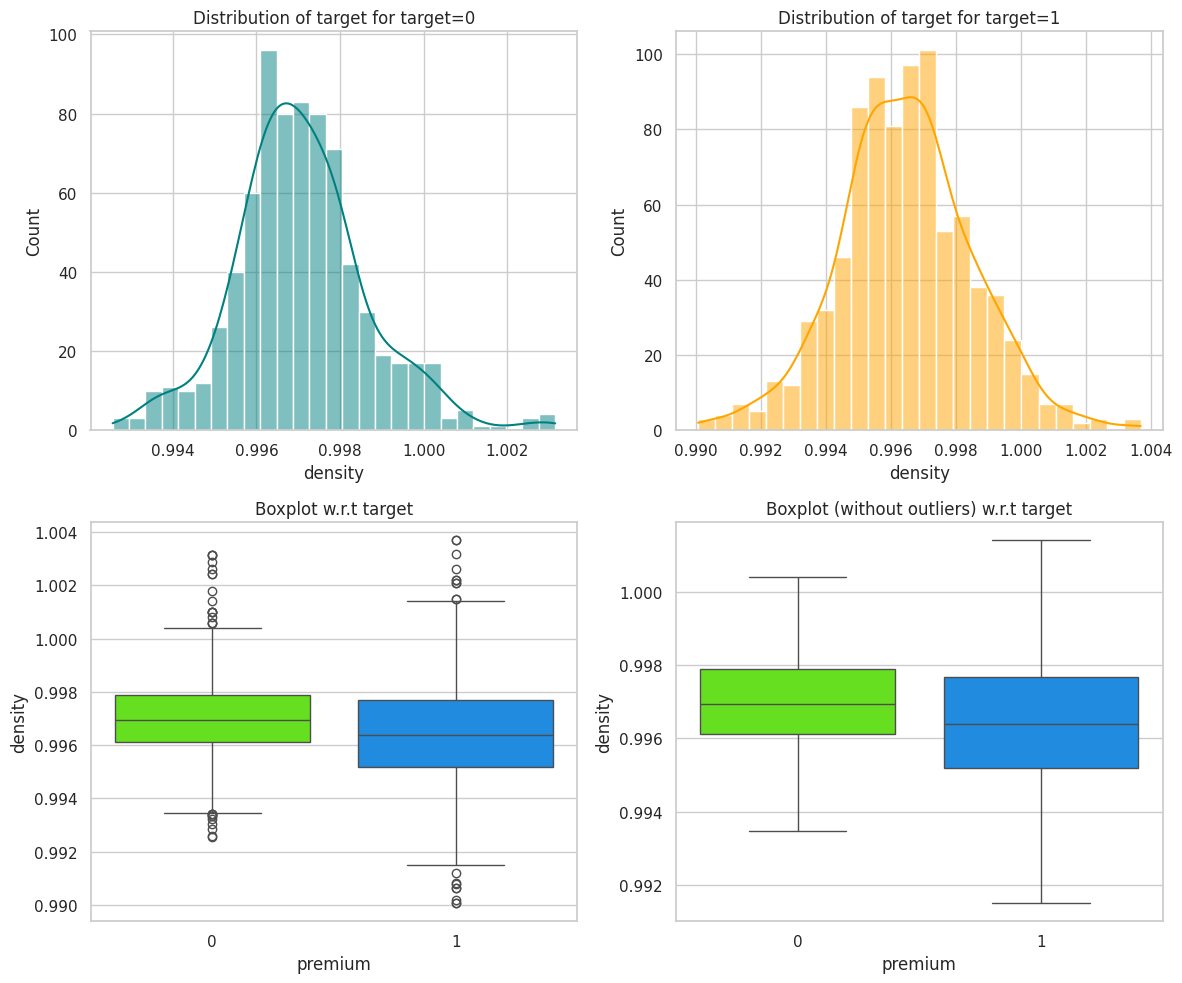

In [ ]:
distribution_plot_wrt_target(data, "density", "premium")

- **Symmetric Bell-Shaped Distributions:** Both target=0 and target=1 follow fairly normal density distributions, peaking around 0.996–0.997.   
- **Slightly Lower & Wider for Premium:** Looking at the boxplots without outliers, premium=1 has a slightly lower median (around 0.9964 vs. 0.9969) and a wider interquartile range (roughly 0.9952–0.9977 compared to 0.9961–0.9979 for premium=0).   
- **Balanced Outliers in Both Classes:** Both groups have outliers on both the low and high ends, with premium=1 reaching slightly more extreme values on either side (down to ~0.990 and up to ~1.0037).   
- **Weak Separator:** Because the core ranges and peaks overlap heavily, density alone provides only weak separation between premium and non-premium wines.

#### `pH vs premium`

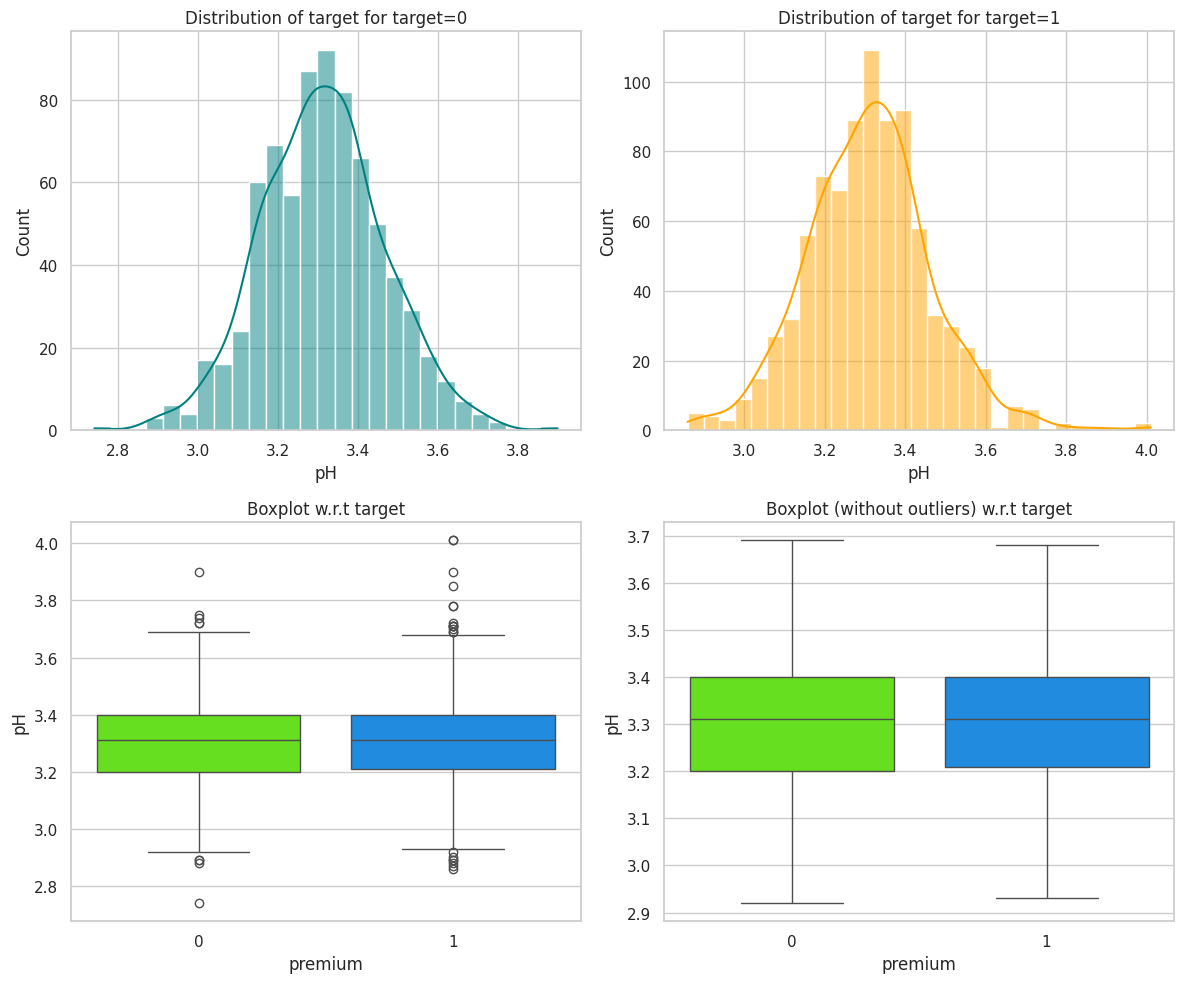

In [ ]:
distribution_plot_wrt_target(data, "pH", "premium")

- **Symmetric Bell-Shaped Distributions:** Both target=0 and target=1 follow very similar normal pH distributions, peaking sharply around 3.3.   
- **Nearly Identical Median and IQR:** Looking at the boxplots without outliers, both premium=0 and premium=1 share almost the exact same median (around 3.31) and interquartile range (roughly 3.20–3.40), with whiskers spanning from ~2.92 to ~3.69.   
- **Outliers on Both Ends:** Both classes have outliers on the low and high ends—premium=0 reaches slightly lower (down to ~2.74), while premium=1 has a few more high-end outliers reaching up to ~4.01.   
- **Very Weak Separator:** Because the distributions, medians, and core spreads overlap almost completely, pH alone offers virtually no power to distinguish between premium and non-premium wines.   

#### `sulphates vs premium`

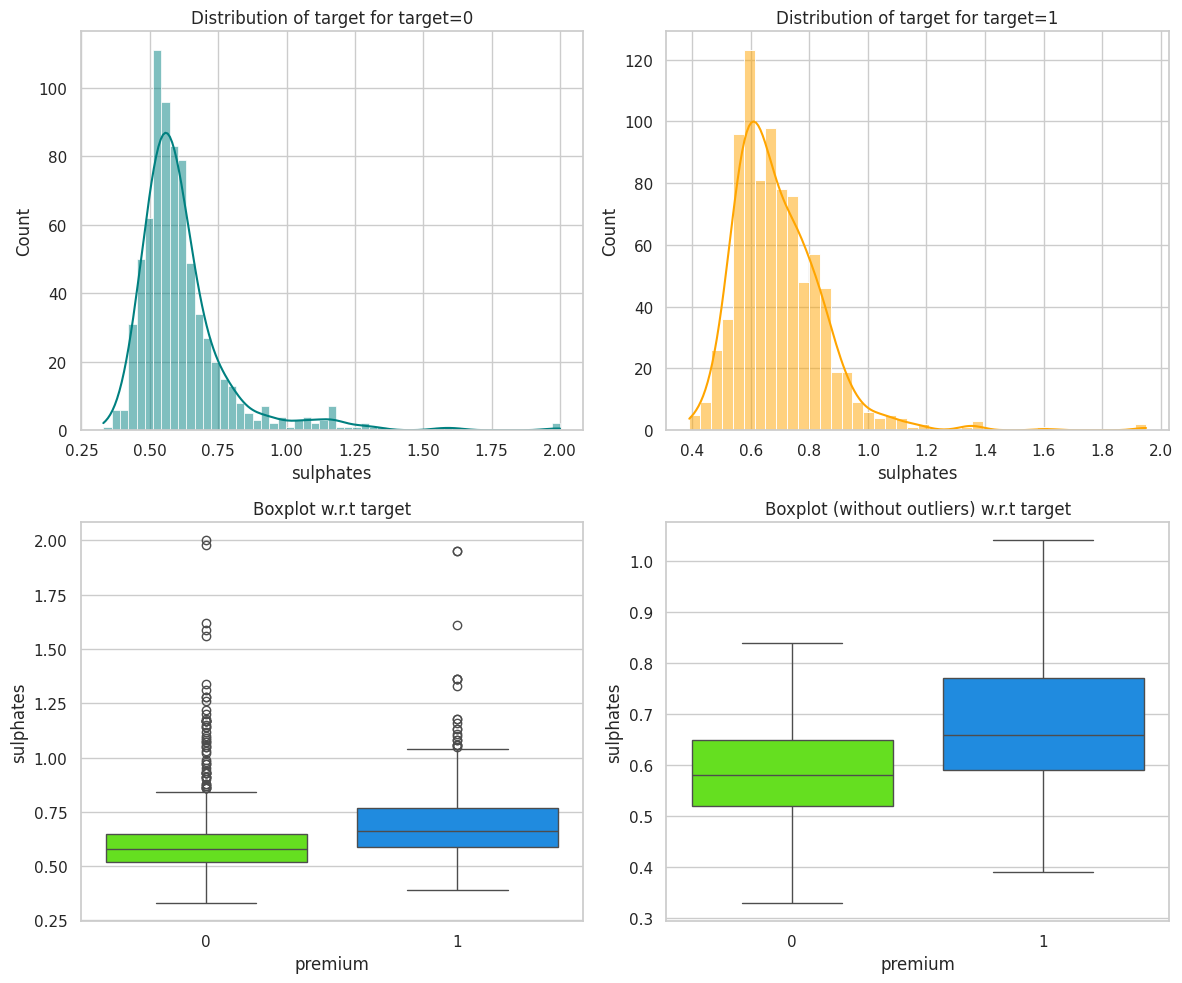

In [ ]:
distribution_plot_wrt_target(data, "sulphates", "premium")

- **Clear Positive Relationship:** Premium wines (target=1) generally have noticeably higher sulphates levels than non-premium wines (target=0).   
- **Shifted Right-Skewed Distributions:** Both classes are right-skewed, but target=0 peaks sharply around 0.52–0.55, whereas target=1 shifts higher with a peak around 0.60 and a heavier spread between 0.60 and 0.85.   
- **Good Separation in Boxplots:** Looking at the boxplots without outliers, premium=1 has a higher median (around 0.66 vs. 0.58) and a higher interquartile range (roughly 0.59–0.77 compared to 0.52–0.65 for premium=0)—in fact, the median of class 1 sits slightly above the 75th percentile of class 0, making sulphates a useful predictor.   
- **Outlier Differences:** Non-premium wines (0) have a dense cluster of high-end outliers starting just above 0.84 and reaching 2.0, while premium wines (1) have a higher upper whisker (~1.04) and fewer outliers reaching ~1.95.  

#### `alcohol vs premium`

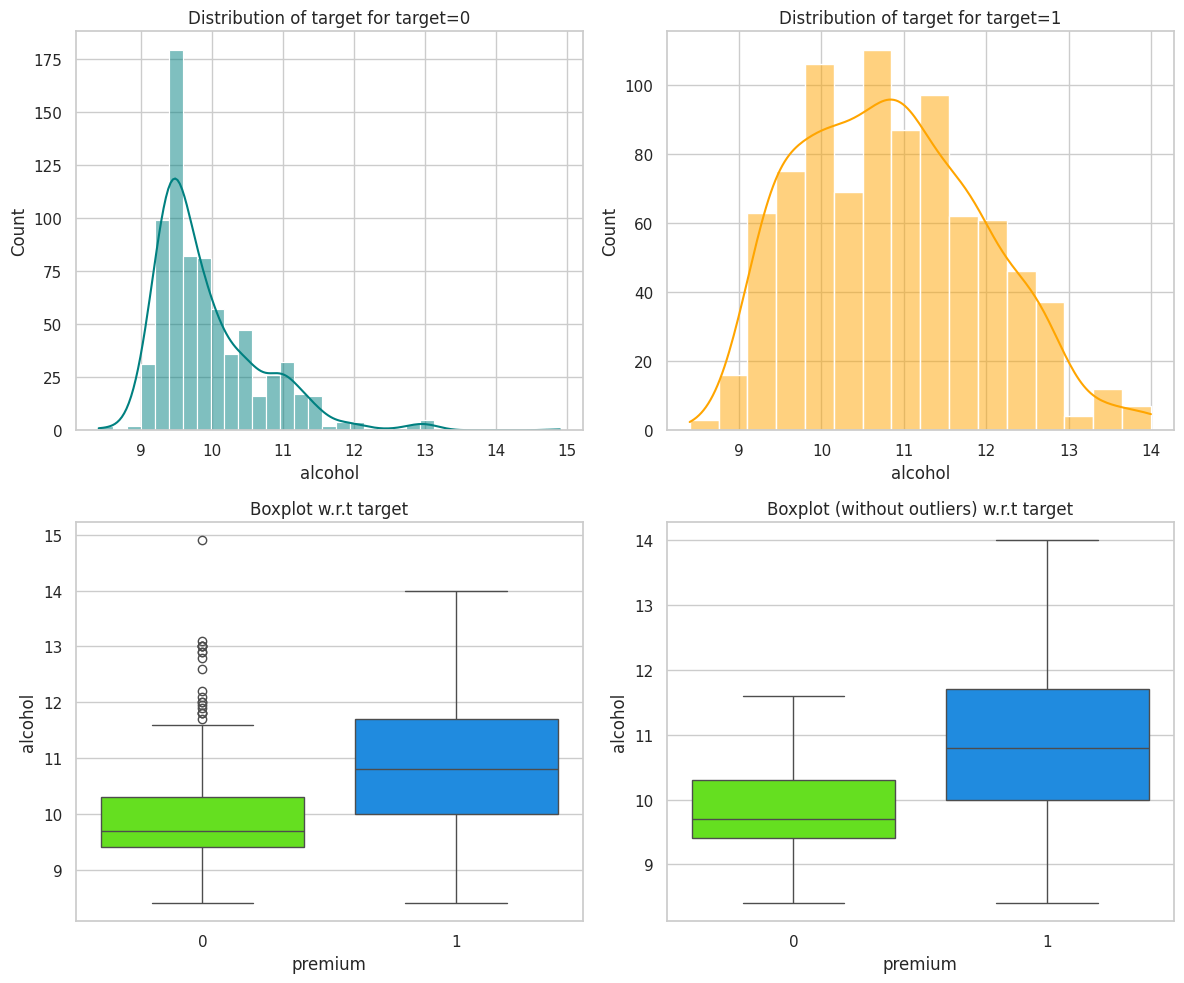

In [ ]:
distribution_plot_wrt_target(data, "alcohol", "premium")

- **Strong Positive Relationship:** Premium wines (target=1) have noticeably higher alcohol content than non-premium wines (target=0).   
- **Distinct Distribution Shapes:** target=0 is strongly right-skewed with a sharp peak right around 9.5, whereas target=1 is much wider and more symmetric, peaking around 10.5–11.0.   
- **Strong Separation in Boxplots:** Looking at the boxplots without outliers, premium=1 has a much higher median (around 10.8 vs. 9.7) and interquartile range (roughly 10.0–11.7 compared to 9.4–10.3 for premium=0)—with the median of class 1 sitting well above the 75th percentile of class 0, making alcohol a strong predictor.   
- **Outliers Only in Non-Premium:** Non-premium wines (0) have several high-end outliers above 11.6 (including one extreme point near 14.9), while premium wines (1) have no outliers at all with an upper whisker reaching 14.0.

### Multivariate Analysis

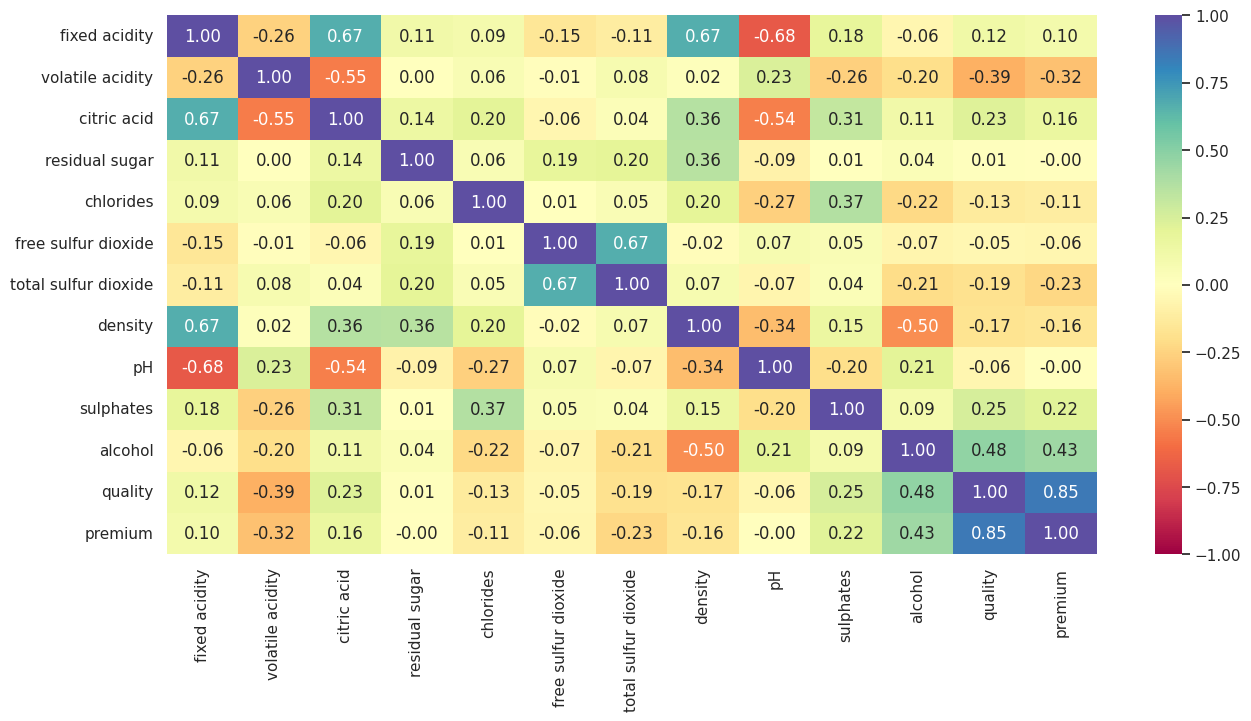

In [ ]:
plt.figure(figsize=(15, 7))
sns.heatmap(data.corr(numeric_only=True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

- **Strongest Predictors of premium:** alcohol has the strongest positive correlation (0.43), while volatile acidity has the strongest negative correlation (-0.32). sulphates (0.22) and total sulfur dioxide (-0.23) also show moderate relationships with the target.   
- **Weakest Linear Features:** residual sugar (-0.00) and pH (-0.00) show virtually zero linear correlation with premium, followed closely by free sulfur dioxide (-0.06).   
image_f5c3ba.

- **High Feature-to-Feature Correlations:** fixed acidity is strongly linked with pH (-0.68), citric acid (0.67), and density (0.67). Other notable pairs include free sulfur dioxide with total sulfur dioxide (0.67), citric acid with volatile acidity (-0.55) and pH (-0.54), and alcohol with density (-0.50).   
- **Target Leakage Check:** quality and premium have a very high correlation of 0.85 because premium was created from quality. Remember to drop the quality column before training your models to prevent data leakage.

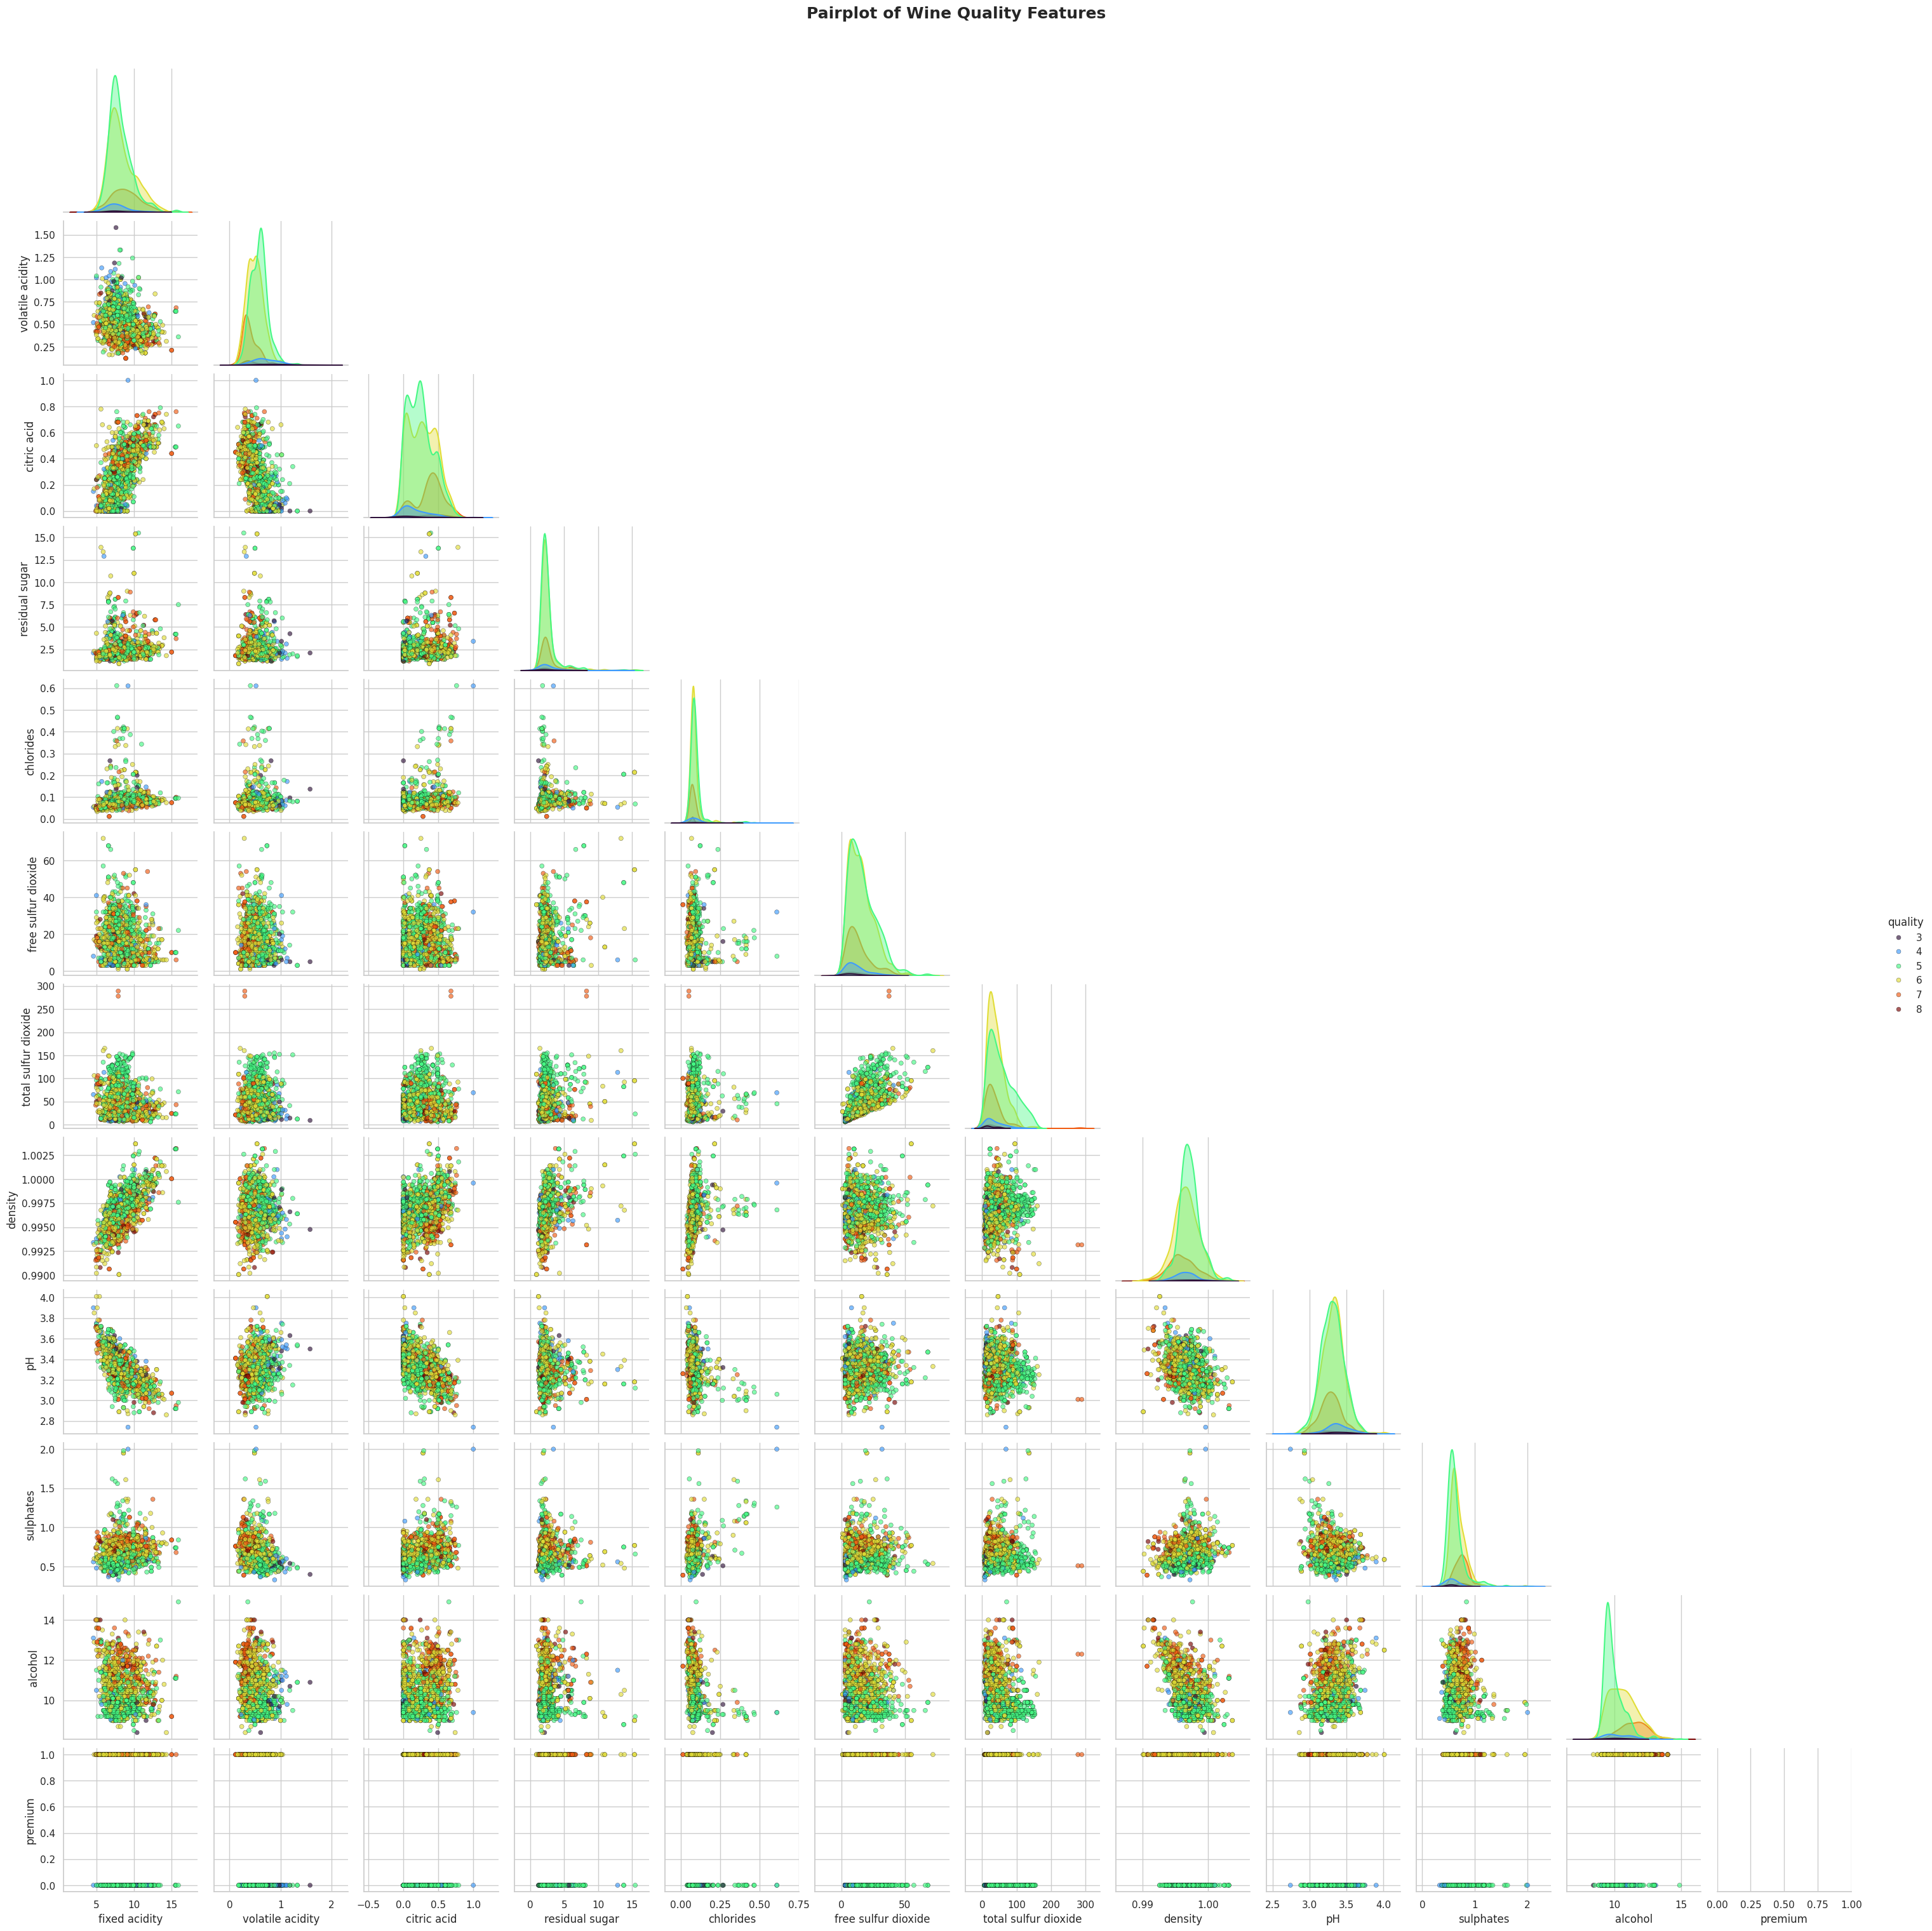

In [ ]:
sns.set_theme(style="whitegrid")

g = sns.pairplot(
    data,
    hue='quality',
    palette='turbo',
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.65, 's': 25, 'edgecolor': 'black', 'linewidth': 0.3},
    diag_kws={'fill': True, 'alpha': 0.4, 'linewidth': 1.5}
)

g.fig.suptitle("Pairplot of Wine Quality Features", y=1.02, fontsize=18, fontweight='bold')
plt.show()

- **Heavy Class Overlap:** Across most scatter plots, the quality ratings (especially 5, 6, and 7) overlap heavily, showing that wine quality cannot be cleanly separated by any single pair of features alone.   
- **Visible Linear Relationships:** Clear diagonal trends stand out between strongly correlated features, such as fixed acidity with citric acid (positive), density (positive), and pH (negative), as well as free vs. total sulfur dioxide (positive) and alcohol vs. density (negative).   
- **Best Visual Separation:** In the alcohol row, higher-quality wines (orange and dark red dots for ratings 7 and 8) cluster noticeably higher on the y-axis, particularly when paired with lower volatile acidity or higher sulphates.   
- **Binary premium Row & Outliers:** The bottom row splits cleanly into two flat lines (0.0 for ratings 3–5 and 1.0 for ratings 6–8), while extreme outliers—like the two total sulfur dioxide points near 280–300—stand out clearly across the grid.   

## Data Preparation for Modeling

### Separate Features and Target


In [ ]:
# Splitting the data into X and y variable
X = data.drop(["quality", "premium"], axis=1)
y = data["premium"]

- `X` contains the chemical properties. `y` contains the answer we want the model to predict.

- We remove `quality` because we are predicting the premium label using the other columns.

### Split the Dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1279, 11)
Testing Data: (320, 11)


- Use 80% of the data for training and 20% for testing.

- 80% of training data is contains 1279 rows and 11 cloumns and 20% testing data is contains 320 rows and 11 columns into the Dataset.

## Building the model

In [ ]:
# defining a function to compute different metrics to check preformance of a classification model built using sklearn

def model_performance_classification_sklearn(model, predictors, target):
  """
  Function to compute different metrics to check classification model preformance

  model: classifier
  predictors: independent variables
  target: dependent variables
  """

  # predicting using the independent variables
  pred = model.predict(predictors)

  acc = accuracy_score(target, pred) # to compute Accuracy
  recall = recall_score(target, pred) # to compute Recall
  precision = precision_score(target, pred) # to compute Precision
  f1 = f1_score(target, pred) # to compute F1-score

  # Creating a dataframe of metrics
  df_perf = pd.DataFrame(
      {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
      index=[0],
  )

  return df_perf

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

### (i). Decision Tree (Baseline Model)

In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

- **Model Setup:** DecisionTreeClassifier is initialized with default settings (criterion='gini', max_depth=None).

- **Reproducibility:** random_state=42 ensures the same results every time you run the code.

In [ ]:
dt_train_perf = model_performance_classification_sklearn(dt, X_train, y_train)
print("Training Performance:")
display(dt_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


- **Perfect Training Score:** Accuracy, Recall, Precision, and F1 are all 1.0 (100%), meaning the model predicted every training sample correctly.

In [ ]:
dt_val_perf = model_performance_classification_sklearn(dt, X_test, y_test)
print("Validation Performance:")
display(dt_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.753125,0.777778,0.764368,0.771014


- **Clear Overfitting:** Accuracy dropped from 1.00 (100%) on training to 0.7531 (~75.3%) on validation—a ~25% gap that confirms the tree memorized the training data.

- **Balanced Metrics:** Recall (0.7778), Precision (0.7644), and F1-score (0.7710) are all very close, meaning the model handles False Positives and False Negatives fairly evenly.

- **Baseline Benchmark:** This sets a baseline of ~75.3% Accuracy and ~77.1% F1-score for your ensemble models to beat.

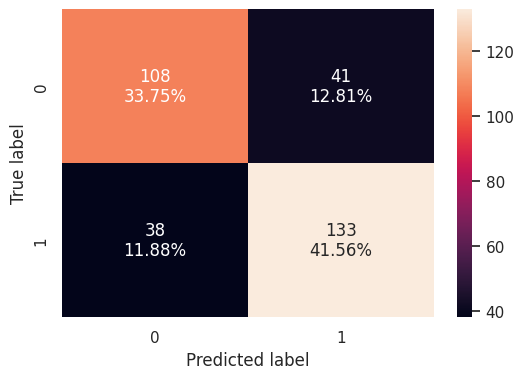

In [ ]:
confusion_matrix_sklearn(dt, X_test, y_test)

- **Correct Predictions:** The model correctly predicted 241 out of 320 samples (75.31%) — 108 True Negatives (class 0) and 133 True Positives (class 1).

- **Total Errors:** It made 79 mistakes (24.69% overall).

- **Balanced Errors:** False Positives (41 or 12.81%) and False Negatives (38 or 11.88%) are nearly equal, meaning the model is not heavily biased toward either class.

### (ii). Bagging Classifier

In [ ]:
bagging = BaggingClassifier(random_state=42)
bagging.fit(X_train, y_train)

BaggingClassifier(random_state=42)

- **Model Setup:** BaggingClassifier is initialized with default settings (n_estimators=10 Decision Trees trained on random bootstrap samples of the training data).

- **Reproducibility:** random_state=42 ensures the same random sampling and results every time you run it.

In [ ]:
bagging_train_perf = model_performance_classification_sklearn(bagging, X_train, y_train)
print("Training Performance:")
display(bagging_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,0.989836,0.98538,0.995569,0.990448


- **Very High Training Score:** All metrics are close to 99% (Accuracy: 98.98%, F1: 99.04%), with Precision reaching 99.56%.

- **Slightly Less Memorization:** Unlike the single Decision Tree (1.00), Bagging is slightly below 100% because each tree only trains on a random subset (bootstrap sample) of the data.

In [ ]:
bagging_val_perf = model_performance_classification_sklearn(bagging, X_test, y_test)
print("Validation Performance:")
display(bagging_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.796875,0.783626,0.82716,0.804805


- **Clear Improvement over Decision Tree:** Validation Accuracy jumped from 75.3% to 79.7%, and F1-score improved from 77.1% to 80.5%.

- **Stronger Precision:** Precision (82.7%) is higher than Recall (78.4%), meaning the model makes fewer False Positive mistakes when predicting class 1.

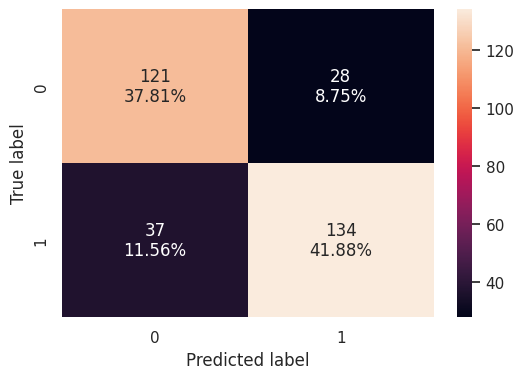

In [ ]:
confusion_matrix_sklearn(bagging, X_test, y_test)

- **More Correct Predictions:** The model correctly classified 255 out of 320 samples (79.69%) — 121 True Negatives (class 0) and 134 True Positives (class 1).

- **Fewer Total Errors:** Mistakes dropped to 65 (20.31%) compared to 79 in the Decision Tree.

- **Big Drop in False Positives:** False Positives fell sharply to 28 (8.75%), while False Negatives stayed similar at 37 (11.56%), explaining the jump in Precision.

### (iii). Random Forest Classifier

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

- **Model Setup:** RandomForestClassifier is initialized with default settings (n_estimators=100 Decision Trees, using both bootstrap sampling and random feature selection at each split).

- **Reproducibility:** random_state=42 ensures the same random splits and results every time you run it.

In [ ]:
rf_train_perf = model_performance_classification_sklearn(rf, X_train, y_train)
print("Training Performance:")
display(rf_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


- **Perfect Training Score:** Accuracy, Recall, Precision, and F1 are all 1.0 (100%), meaning the model classified every training sample correctly.

In [ ]:
rf_val_perf = model_performance_classification_sklearn(rf, X_test, y_test)
print("Validation Performance:")
display(rf_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.80625,0.795322,0.834356,0.814371


- **Best Model So Far:** Validation Accuracy reached 80.6% and F1-score hit 81.4%, beating both the Decision Tree (75.3%) and Bagging (79.7%).

- **Strong Precision & Balanced Recall:** Precision (83.4%) is the highest yet, and Recall (79.5%) also improved, meaning fewer False Positives and False Negatives overall.

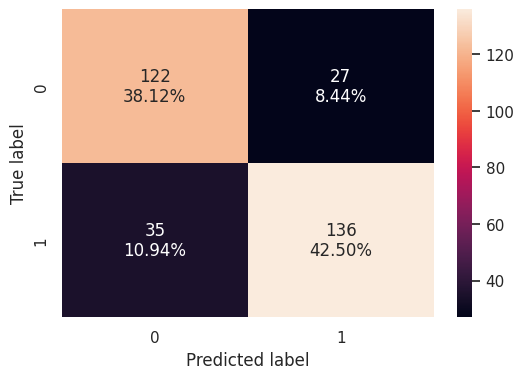

In [ ]:
confusion_matrix_sklearn(rf, X_test, y_test)

- **Highest Correct Predictions Yet:** The model correctly classified 258 out of 320 samples (80.62%) — 122 True Negatives (class 0) and 136 True Positives (class 1).

- **Lowest Total Errors:** Mistakes dropped further to 62 (19.38%), beating both Bagging (65 errors) and Decision Tree (79 errors).

- **Balanced Improvement:** Both False Positives (27 or 8.44%) and False Negatives (35 or 10.94%) decreased slightly compared to Bagging, showing better overall accuracy across both classes.

### (iv). AdaBoost Classifier

In [ ]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

AdaBoostClassifier(random_state=42)

- **Model Setup:** AdaBoostClassifier is initialized with default settings (n_estimators=50, learning_rate=1.0, using shallow Decision Stumps as weak learners).

- **Reproducibility:** random_state=42 ensures the same results every time you run the code.

In [ ]:
ada_train_perf = model_performance_classification_sklearn(ada, X_train, y_train)
print("Training Performance:")
display(ada_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,0.779515,0.776316,0.804545,0.790179


- **No Memorization:** Unlike Decision Tree (100%), Bagging (99%), and Random Forest (100%), AdaBoost has a much lower training score (78.0% Accuracy, 79.0% F1) because it uses shallow trees (decision stumps).

- **Balanced Performance:** Precision (80.5%) is slightly higher than Recall (77.6%), giving a solid, balanced F1-score.

In [ ]:
ada_val_perf = model_performance_classification_sklearn(ada, X_test, y_test)
print("Validation Performance:")
display(ada_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.73125,0.71345,0.767296,0.739394


- **Lowest Validation Score So Far:** Accuracy (73.1%) and F1-score (73.9%) are lower than Decision Tree (75.3%), Bagging (79.7%), and Random Forest (80.6%).

- **Very Little Overfitting:** The gap between Training (78.0%) and Validation (73.1%) accuracy is small (~4.8%), showing good stability, though the model is slightly underfitting with default shallow trees.

- **Precision Over Recall:** Precision (76.7%) is higher than Recall (71.3%), meaning it misses more positive cases (False Negatives) than it falsely flags.

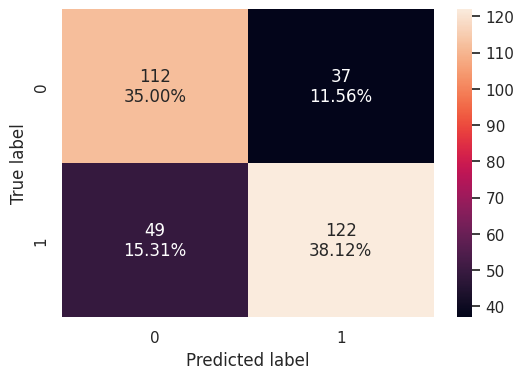

In [ ]:
confusion_matrix_sklearn(ada, X_test, y_test)

- **Fewer Correct Predictions:** The model correctly classified 234 out of 320 samples (73.12%) — 112 True Negatives (class 0) and 122 True Positives (class 1).

- **Highest Total Errors So Far:** Mistakes rose to 86 (26.88%), which is higher than Random Forest (62), Bagging (65), and Decision Tree (79).

- **High False Negatives:** It missed 49 actual class 1 cases (15.31%), noticeably more than its 37 False Positives (11.56%), explaining the lower Recall score.

### (v). Gradient Boosting Classifier

In [ ]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

- **Model Setup:** GradientBoostingClassifier is initialized with default settings (n_estimators=100, learning_rate=0.1, max_depth=3).

- **Reproducibility:** random_state=42 ensures you get the same results every time you run the code.

In [ ]:
gb_train_perf = model_performance_classification_sklearn(gb, X_train, y_train)
print("Training Performance:")
display(gb_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,0.870211,0.874269,0.882006,0.87812


- **Strong, Controlled Training Score:** Accuracy is 87.0% and F1-score is 87.8%—much higher than AdaBoost (78.0%), without memorizing the data like Decision Tree or Random Forest (100%).

- **Well-Balanced Metrics:** Precision (88.2%) and Recall (87.4%) are very close, showing the model handles both classes evenly.

In [ ]:
gb_val_perf = model_performance_classification_sklearn(gb, X_test, y_test)
print("Validation Performance:")
display(gb_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.790625,0.766082,0.829114,0.796353


- **Solid Performance:** Validation Accuracy is 79.1% and F1-score is 79.6%. While slightly behind Random Forest (80.6%) and Bagging (79.7%), the train-to-validation gap is much smaller (~8% vs. ~19%), meaning it generalizes more reliably.

- **High Precision, Lower Recall:** Precision (82.9%) is strong, but Recall (76.6%) is noticeably lower—meaning it makes fewer False Positives but misses more actual class 1 cases.

- **Clear Upgrade Over AdaBoost:** It easily outperforms both AdaBoost (73.1%) and the single Decision Tree (75.3%).

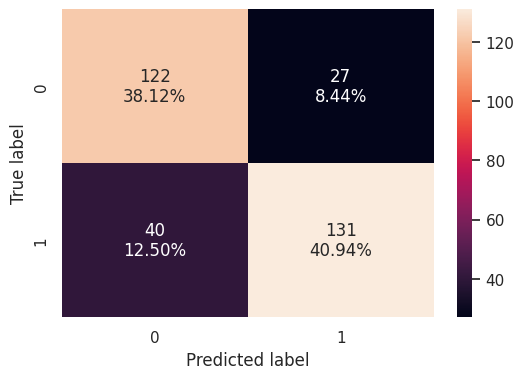

In [ ]:
confusion_matrix_sklearn(gb, X_test, y_test)

- **Correct Predictions:** The model correctly classified 253 out of 320 samples (79.06%) — 122 True Negatives (class 0) and 131 True Positives (class 1).

- **Total Errors:** It made 67 mistakes (20.94%), which is much better than AdaBoost (86 errors) and Decision Tree (79 errors), and very close to Bagging (65 errors).

- **Low False Positives, Higher False Negatives:** It matched Random Forest's best False Positive count (27 or 8.44%), but missed 40 actual class 1 cases (12.50%), explaining the slightly lower Recall.

### (vi). XGBoost Classifier (eXtreme Gradient Boosting Classifier)

In [ ]:
xgb = XGBClassifier(random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

- **Model Setup:** XGBClassifier is initialized with its default core settings (n_estimators=100, max_depth=6, learning_rate=0.3 under the hood), along with eval_metric='logloss' for binary classification and enable_categorical=True.

- **Key Advantage:** Unlike standard Gradient Boosting, XGBoost adds built-in L1 and L2 regularization to help control overfitting while capturing more complex patterns.

In [ ]:
xgb_train_perf = model_performance_classification_sklearn(xgb, X_train, y_train)
print("Training Performance:")
display(xgb_train_perf)

Training Performance:


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


- **Perfect Training Score:** Accuracy, Recall, Precision, and F1 are all 1.0 (100%), meaning XGBoost memorized every training sample.

- **Why It Happened:** With its default max_depth=6 and learning_rate=0.3, the model is aggressive enough to fit the training data completely—unlike GradientBoostingClassifier (87.0%).

In [ ]:
xgb_val_perf = model_performance_classification_sklearn(xgb, X_test, y_test)
print("Validation Performance:")
display(xgb_val_perf)

Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.8125,0.812865,0.832335,0.822485


- **New Best Model So Far:** Validation Accuracy climbed to 81.25% and F1-score hit 82.25%, beating Random Forest (80.6% Accuracy, 81.4% F1) for the top spot.

- **Best Balance of Precision & Recall:** Recall jumped to 81.3% (the highest yet) while keeping Precision very strong at 83.2%, meaning it catches more actual class 1 cases without sacrificing much precision.

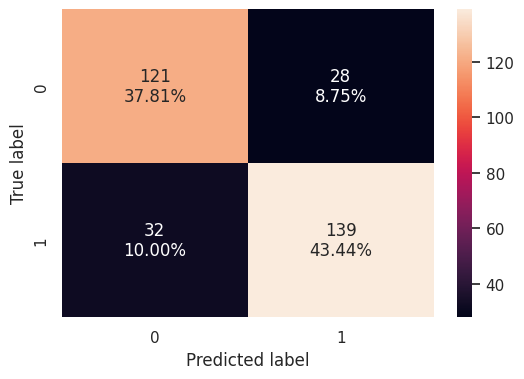

In [ ]:
confusion_matrix_sklearn(xgb, X_test, y_test)

- **Best Correct Predictions Yet:** The model correctly classified 260 out of 320 samples (81.25%) — 121 True Negatives (class 0) and 139 True Positives (class 1).

- **Lowest Total Errors:** Mistakes dropped to 60 (18.75%), beating Random Forest (62), Bagging (65), and Gradient Boosting (67).

- **Lowest False Negatives:** It missed only 32 actual class 1 cases (10.00%) while keeping False Positives very low at 28 (8.75%), which explains why it achieved the highest Recall and F1-score so far.

### **Training Performance Comparison**

In [ ]:
models_train_comp_df = pd.concat(
    [
        dt_train_perf.T,
        bagging_train_perf.T,
        rf_train_perf.T,
        ada_train_perf.T,
        gb_train_perf.T,
        xgb_train_perf.T,
    ],
    axis=1,
)

models_train_comp_df.columns = [
    "Decision Tree",
    "Bagging",
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting",
    "XGBoost",
]

print("Training performance comparison:")
display(models_train_comp_df)

Training performance comparison:


,Decision Tree,Bagging,Random Forest,AdaBoost,Gradient Boosting,XGBoost
Accuracy,1.0,0.989836,1.0,0.779515,0.870211,1.0
Recall,1.0,0.985380,1.0,0.776316,0.874269,1.0
Precision,1.0,0.995569,1.0,0.804545,0.882006,1.0
F1,1.0,0.990448,1.0,0.790179,0.878120,1.0


- **Memorized the Training Data:** Decision Tree, Random Forest, and XGBoost all hit a perfect 1.0 (100%) across every metric, with Bagging right behind at ~99%. This shows high model complexity and a strong tendency to overfit on default settings.

- **Controlled Learning:** Gradient Boosting sits in the middle at 87.0% Accuracy and 87.8% F1, learning strong patterns without memorizing the dataset thanks to its shallow default trees (max_depth=3).

- **Underfitting Signal:** AdaBoost has the lowest training scores (78.0% Accuracy, 79.0% F1), indicating its default decision stumps are too simple to fully capture the data's complexity.

### **Validation Performance Comparision**

In [ ]:
models_val_comp_df = pd.concat(
    [
        dt_val_perf.T,
        bagging_val_perf.T,
        rf_val_perf.T,
        ada_val_perf.T,
        gb_val_perf.T,
        xgb_val_perf.T,
    ],
    axis=1,
)

models_val_comp_df.columns = [
    "Decision Tree",
    "Bagging",
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting",
    "XGBoost",
]

print("Validation performance comparison:")
display(models_val_comp_df)

Validation performance comparison:


,Decision Tree,Bagging,Random Forest,AdaBoost,Gradient Boosting,XGBoost
Accuracy,0.753125,0.796875,0.806250,0.731250,0.790625,0.812500
Recall,0.777778,0.783626,0.795322,0.713450,0.766082,0.812865
Precision,0.764368,0.827160,0.834356,0.767296,0.829114,0.832335
F1,0.771014,0.804805,0.814371,0.739394,0.796353,0.822485



- **Top Performer — XGBoost:** Leads the pack across almost every metric with 81.25% Accuracy, 81.29% Recall, and 82.25% F1-score, making it the strongest default model on unseen data.

- **Close Runner-Up — Random Forest:** Finishes second overall (80.63% Accuracy, 81.44% F1) and actually edges out XGBoost slightly for the highest Precision (83.44%).

- **Best Generalization — Gradient Boosting:** Although it sits fourth in raw validation accuracy (79.06%, just behind Bagging's 79.69%), it has a much smaller train-to-validation gap (~ 8%) compared to XGBoost, Random Forest, and Bagging (~ 18 – 19%), meaning it overfits far less.

- **Weakest Models — AdaBoost & Decision Tree:** AdaBoost (73.13% Accuracy) underfits due to its shallow default trees, while the single Decision Tree (75.31% Accuracy) suffers the worst overfitting (~25% drop from training).

### Hyperparameter Tuning

### (i). Tune XGBoost Classifier

In [ ]:
# Define the parameter grid to control tree complexity and overfitting
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],           # Lower depth reduces memorization
    'learning_rate': [0.01, 0.05, 0.1],  # Smaller steps help generalization
    'subsample': [0.7, 0.8, 1.0],        # Row sampling
    'colsample_bytree': [0.7, 0.8, 1.0], # Feature sampling
    'min_child_weight': [1, 3, 5]        # Minimum samples needed to split
}

xgb_tuned = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_distributions=param_grid_xgb,
    n_iter=30,             # Tests 30 random combinations
    scoring='f1',          # Optimizes for F1-score
    cv=5,                  # 5-fold cross-validation
    random_state=42,
    n_jobs=-1
)

xgb_tuned.fit(X_train, y_train)

print("Best Parameters:", xgb_tuned.best_params_)
best_xgb = xgb_tuned.best_estimator_

Best Parameters: {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


- **Slower, Steadier Learning (n_estimators=300, learning_rate=0.05):** Tripled from the default 100 trees while lowering the learning rate from 0.3, which helps the model learn patterns more carefully and generalize better.

- **Controlled Tree Depth (max_depth=5, min_child_weight=1):** Slightly shallower than the default depth of 6 while keeping the default leaf weight, preventing the trees from completely memorizing the training data.

- **Random Sampling (subsample=0.7, colsample_bytree=0.7):** Uses a random 70% of rows and 70% of features for each tree instead of 100%, which adds randomness and directly helps reduce overfitting.

In [ ]:
xgb_tuned_train_perf = model_performance_classification_sklearn(best_xgb, X_train, y_train)
print("Tuned XGBoost - Training Performance:")
display(xgb_tuned_train_perf)

Tuned XGBoost - Training Performance:


,Accuracy,Recall,Precision,F1
0,0.986708,0.988304,0.986861,0.987582


- **Slight Drop from 100%:** Training Accuracy dropped slightly from 100% to 98.67% (and F1 to 98.76%), showing the tuning stopped the model from completely memorizing every training sample.

- **Still Very High:** At ~98.7%, the model is still fitting the training data very closely, so there may still be some overfitting.

In [ ]:
xgb_tuned_val_perf = model_performance_classification_sklearn(best_xgb, X_test, y_test)
print("\nTuned XGBoost - Validation Performance:")
display(xgb_tuned_val_perf)


Tuned XGBoost - Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.83125,0.818713,0.858896,0.838323


- **Clear New Best Model:** Validation Accuracy jumped to 83.13% (up from 81.25%) and F1-score climbed to 83.83% (up from 82.25%)—the strongest performance across every metric so far.

- **Big Boost in Precision:** Precision rose sharply to 85.89% (+2.7%), while Recall also edged up to 81.87%, meaning fewer False Positives without losing your ability to catch class 1 cases.

- **Reduced Overfitting:** The train-to-validation gap shrank from ~18.8% (default XGBoost) to ~15.5% (98.7% train vs. 83.1% validation), confirming that tuning genuinely improved generalization.

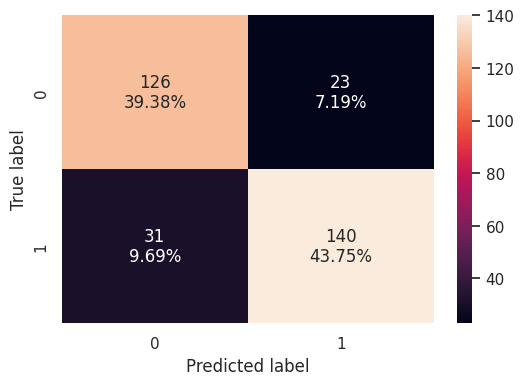

In [ ]:
confusion_matrix_sklearn(best_xgb, X_test, y_test)

- **Best Correct Predictions Overall:** The model correctly classified 266 out of 320 samples (83.13%) — 126 True Negatives (class 0) and 140 True Positives (class 1).

- **Lowest Total Errors:** Mistakes dropped to just 54 (16.88%), cutting 6 more errors compared to the default XGBoost (60 errors).

- **Noticeable Drop in False Positives:** False Positives fell to 23 (7.19%, down from 28), while False Negatives also edged down to 31 (9.69%, down from 32), explaining the jump in both Precision and F1-score.

### (ii). Tune Random Forest Classifier

In [ ]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

rf_tuned = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid_rf,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)
print("Best RF Parameters:", rf_tuned.best_params_)
best_rf = rf_tuned.best_estimator_

Best RF Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}


- **More Trees (n_estimators=200):** Doubled from the default 100 trees, which helps stabilize predictions and slightly reduce variance.

- **Same Full Depth (max_depth=None, min_samples_split=2, min_samples_leaf=1):** The search kept the trees fully grown, meaning the training score will likely still be 100% (1.0).

- **Feature Selection (max_features='log2'):** Uses log2 instead of sqrt at each split—for this dataset's ~11 features, both select 3 features per split, so the main change is having 200 trees.

In [ ]:
rf_tuned_train_perf = model_performance_classification_sklearn(best_rf, X_train, y_train)
print("Tuned RF - Training Performance:")
display(rf_tuned_train_perf)

Tuned RF - Training Performance:


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


- **Still 100% on Training:** Accuracy, Recall, Precision, and F1 all stayed at 1.0 (100%), exactly as expected since max_depth=None and min_samples_leaf=1 let the trees grow to full depth.

In [ ]:
rf_tuned_val_perf = model_performance_classification_sklearn(best_rf, X_test, y_test)
print("\nTuned RF - Validation Performance:")
display(rf_tuned_val_perf)


Tuned RF - Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.815625,0.812865,0.837349,0.824926


- **Improved Over Default RF:** Validation Accuracy rose to 81.56% (up from 80.63%) and F1-score hit 82.49% (up from 81.44%), with Recall seeing the biggest jump (+1.8%).

- **Still Behind Tuned XGBoost:** Tuned XGBoost remains the clear winner across every metric (83.13% Accuracy, 83.83% F1, 85.89% Precision).

- **Overfitting Persists:** The train-to-validation gap is still ~18.4% (100% train vs. 81.56% validation), larger than Tuned XGBoost's ~15.5% gap.

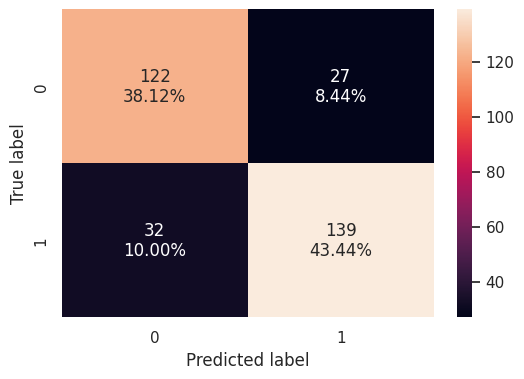

In [ ]:
confusion_matrix_sklearn(best_rf, X_test, y_test)

- **More Correct Predictions Than Default RF:** The model correctly classified 261 out of 320 samples (81.56%) — 122 True Negatives (class 0) and 139 True Positives (class 1).

- **Fewer False Negatives:** Total mistakes dropped to 59 (18.44%), cutting 3 False Negatives compared to the default Random Forest (32 vs. 35) while keeping False Positives identical at 27 (8.44%).

- **Still Behind Tuned XGBoost:** It makes 5 more errors overall than Tuned XGBoost (59 vs. 54), confirming Tuned XGBoost as your strongest model.

# <a name='link2'>Final Validation Comparison</a>

| Model | Accuracy | Recall | Precision | F1-Score |
| :--- | :---: | :---: | :---: | :---: |
| **Tuned XGBoost** | **83.13%** | **81.87%** | **85.89%** | **83.83%** |
| Tuned Random Forest | 81.56% | 81.29% | 83.73% | 82.49% |
| XGBoost (Default) | 81.25% | 81.29% | 83.23% | 82.25% |
| Random Forest (Default) | 80.63% | 79.53% | 83.44% | 81.44% |
| Bagging | 79.69% | 78.36% | 82.72% | 80.48% |
| Gradient Boosting | 79.06% | 76.61% | 82.91% | 79.64% |
| Decision Tree | 75.31% | 77.78% | 76.44% | 77.10% |
| AdaBoost | 73.13% | 71.35% | 76.73% | 73.94% |

#### <a name='link2'>Tuned XGBoost is the best model. It achieved the highest validation scores across every metric: 83.13% Accuracy, 81.87% Recall, 85.89% Precision, and 83.83% F1-score.</a>

#### **Final Observations**
- **Lowest Errors:** Tuned XGBoost correctly predicted 266 out of 320 validation samples and made only 54 errors (23 False Positives and 31 False Negatives), the lowest among all models.
- **Tuning Worked Well:** Setting max_depth=5, learning_rate=0.05, and subsample/colsample_bytree=0.7 reduced overfitting (the train-to-validation gap dropped from ~18.8% to ~15.5%) and boosted validation accuracy by nearly 2%.
- **Ensembles Beat Single Trees:** The single Decision Tree overfitted heavily (100% training vs. 75.31% validation). Ensemble methods like Bagging, Random Forest, and Boosting performed much better on unseen data.
- **Runner-Up & Other Models:** Tuned Random Forest came in second (81.56% accuracy, 59 errors). Gradient Boosting (79.06%) showed the least overfitting (~8% gap), while AdaBoost (73.13%) underfitted slightly due to its shallow default trees.   

**Overall, Tuned XGBoost is the most accurate and well-balanced model for predicting premium wine in this dataset and should be selected as the final model.**

<a name='link2'>**<center><font size=6>Conclusions and Business Recommendations</font></center>**</a>

- **Adopt Tuned XGBoost as the Final Model:** Tuned XGBoost achieved the highest validation performance (83.13% Accuracy and 83.83% F1-score), outperforming all other default and tuned models. It should be deployed as the primary automated classification tool to identify premium wines.
- **Protect Brand Reputation with High Precision:** With a strong Precision of 85.89% and only 23 False Positives out of 320 validation samples, the model rarely misclassifies ordinary wine as premium. This directly protects brand value and prevents customer dissatisfaction.
- **Maximize Revenue Through Strong Recall:** Achieving 81.87% Recall means the model successfully captures more than 8 out of 10 truly premium wine batches, reducing the risk of underpricing high-quality stock.
- **Use Ensembles Over Simple Models:** The single Decision Tree (75.31%) suffered from heavy overfitting, and AdaBoost (73.13%) underfitted the data. For complex physicochemical datasets, the business should rely on tuned ensemble methods like XGBoost or Random Forest (81.56%, 59 errors) rather than simple rule-based models.
- **Monitor Chemical Outliers in Production:** Features such as residual sugar, total sulfur dioxide, free sulfur dioxide, and chlorides contain extreme high-end values. Winemakers should set stricter quality-control checks on these chemical levels during fermentation to keep batches consistent.
- **Reduce Tasting Costs with Automated Screening:** Deploying this model as a first-stage filter can save time and money on manual wine-tasting panels, allowing human experts to focus their efforts only on borderline or high-stakes batches.   

**This project demonstrates the effectiveness of ensemble learning and hyperparameter tuning on wine quality classification. Future improvements can explore feature engineering, additional algorithms like LightGBM or CatBoost, and deeper hyperparameter searches to push validation accuracy even higher.**